# Question D: When do citations peak, and which papers become "high hitters"?

## Identify peak timing using Kaplan–Meier approach

**Question:** How many years after publication do FSR papers typically peak?

**Framing:** we treat "time to citation peak" as a *duration / survival-analysis* problem rather than a plain descriptive statistic. This is deliberate:

- Papers published recently may not have peaked yet, so we simply don't know their peak age. This is **right-censoring**, and a plain mean/median over *observed* peak ages would be biased downward if we ignored it (we'd be systematically excluding papers whose true peak lies further in the future).
- Kaplan–Meier (KM) is the standard non-parametric way to estimate a time-to-event distribution in the presence of censoring, and it lets us report **quantiles** (e.g. median peak age) with a defensible estimator rather than an ad-hoc average.


### 1.1 Setup

For each paper $i = 1, \dots, N$ define:

- $T_i$: the **age at citation peak** (years since publication), the *event time*, if observed.
- $C_i$: the **censoring time**. For papers that have not yet had the chance to peak (e.g. published too recently, or still on a rising citation trajectory as of the data cut-off), this is how long we've been able to observe them so far.
- $\delta_i \in \{0, 1\}$: event indicator, $\delta_i = 1$ if the peak was actually observed, $\delta_i = 0$ if the paper is censored (we only know it hasn't peaked by $C_i$).
- Observed duration: $X_i = \min(T_i, C_i)$.

So each paper contributes a pair $(X_i, \delta_i)$ to the estimator.

### 1.2 The Kaplan–Meier estimator

Let $t_{(1)} < t_{(2)} < \dots < t_{(k)}$ be the distinct observed **event** times (i.e. distinct peak ages actually seen in the data, ignoring censoring times). At each event time $t_{(j)}$ define:

- $n_j$ = number of papers still **at risk** just before $t_{(j)}$ (i.e. not yet peaked and not yet censored, i.e. durations $\geq t_{(j)}$),
- $d_j$ = number of papers whose peak is observed exactly at $t_{(j)}$.

The Kaplan–Meier estimator of the **survival function**, here the probability that a paper has *not yet peaked* by time $t$, is:

$$
\hat S(t) \;=\; \prod_{j:\, t_{(j)} \le t} \left(1 - \frac{d_j}{n_j}\right)
$$

with $\hat S(t) = 1$ for $t$ before the first event. $\hat S(t)$ is a step function that starts at 1 and drops at each observed peak time; it only ever drops at *event* times, not at censoring times (censored papers simply leave the risk set).

### 1.3 Getting the quantile we actually want

The $p$-th quantile of the peak-age distribution, $t_p$, is defined directly from the estimated survival curve as

$$
t_p \;=\; \inf\{\, t : \hat S(t) \le 1-p \,\}
$$

So the **median peak age** is

$$
t_{0.5} \;=\; \inf\{\, t : \hat S(t) \le 0.5 \,\}
$$

i.e. the first time at which the estimated fraction of papers that have *not yet* peaked drops to (or below) 50%. We'll pull this, and the 25th/75th percentiles for a spread, directly off the fitted KM curve.

*(Variance / confidence intervals on $\hat S(t)$ use Greenwood's formula, which `lifelines` computes automatically; we report the CI bands on the quantiles for completeness.)*


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True


### 1.4 Data

Two files, both expected in the same folder as this notebook:

- **`fsr_citations_by_year_openalex.csv`**: long format, one row per (paper, citation year): `doi`, `fsr_pub_year`, `citation_year`, `years_since_pub`, `cites_that_year`, `source`. This is what lets us build a yearly citation curve per paper.
- **`master_dataset.csv`**: one row per paper (Scopus export): includes `doi`, `year` (publication year), `cited_by` (total citations), plus metadata. This gives us the *full* paper roster, including papers with zero citations that never show up in the citations-by-year file at all.

A few real quirks in this data that the pipeline below handles explicitly:

1. **Duplicate sources.** Each (doi, citation_year) can appear twice, once tagged `openalex` and once `openalex_citing_works`, from two different OpenAlex pulls. They agree ~99.5% of the time where both exist, so we keep one (`openalex_citing_works`, the richer of the two pulls) rather than double-counting.
2. **Negative `years_since_pub`.** A handful of rows have citations dated *before* the paper's recorded publication year (preprint/working-paper artefacts). These are dropped, since they're not valid "age since publication" observations.
3. **The current year is partial.** Today is mid-September 2026, so 2026 citation counts are incomplete and would make very recent papers look like they've already "peaked" and declined, when really the year just isn't over. We therefore treat **2025 as the last complete year** and don't use 2026 counts at all when identifying peaks.
4. **Zero-citation papers.** ~60% of papers in `master_dataset.csv` never appear in the citations file at all, because OpenAlex found no citing works for them. These aren't "peaked at age 0"; they simply haven't been cited (yet), so they're included as **censored at their current age**, not as an observed event.

**Censoring rule actually used:** a paper's peak is only counted as *observed* ($\delta_i=1$) if we've seen at least one full year *after* the annual-citation maximum, i.e. we've had the chance to see it decline (or at least plateau) and it's still the max. If the maximum citation year is the very last year we can observe (or the paper has zero citations to date), we don't yet know if it's still rising, so it's **right-censored** at its current age.


In [2]:
LAST_COMPLETE_YEAR = 2025  # 2026 is only partially observed as of this data pull (mid-Sept 2026)

cit = pd.read_csv("../data/fsr_citations_by_year_openalex.csv")
master = pd.read_csv("../data/master_dataset.csv")

# 1) Dedup the two OpenAlex sources for the same (doi, citation_year); keep 'openalex_citing_works',
#    the richer pull (449 DOIs / 3,077 rows vs 421 / 1,957). The two agree ~99.5% where both exist.
cit = cit[cit["source"] == "openalex_citing_works"]

# 2) Drop invalid ages and the incomplete current year.
cit = cit[(cit["years_since_pub"] >= 0) & (cit["citation_year"] <= LAST_COMPLETE_YEAR)]

# 3) Full paper roster: every FSR paper with a DOI and a valid, complete publication age.
#    (master_dataset.csv also contains two other journals -- restrict to Financial Services Review.)
master_fsr = master[master["source_title"] == "Financial Services Review"]
papers = (master_fsr.dropna(subset=["doi"])
                 .drop_duplicates(subset="doi")[["doi", "year"]]
                 .rename(columns={"year": "pub_year"}))
papers = papers[papers["pub_year"] <= LAST_COMPLETE_YEAR].copy()
papers["current_age"] = LAST_COMPLETE_YEAR - papers["pub_year"]

# 4) Per-paper annual citation counts, keyed by (doi, age).
annual = cit.groupby(["doi", "years_since_pub"])["cites_that_year"].sum().reset_index()
annual_lookup = annual.set_index(["doi", "years_since_pub"])["cites_that_year"]

def peak_and_event(doi, current_age):
    """Build the full 0..current_age citation series (missing years = 0 citations),
    then apply the censoring rule from the markdown above."""
    series = np.zeros(current_age + 1)
    for age in range(current_age + 1):
        series[age] = annual_lookup.get((doi, age), 0)
    total = series.sum()
    if total == 0:
        return current_age, 0                     # never cited yet -> censored
    peak_age = int(np.argmax(series))              # first max in case of ties
    if peak_age < current_age:
        return peak_age, 1                         # decline observed after the peak -> event
    return current_age, 0                          # peak sits at the edge of observation -> censored

results = [peak_and_event(row.doi, row.current_age) for row in papers.itertuples()]
papers["peak_age"], papers["peaked"] = zip(*results)

df = papers.rename(columns={"peak_age": "peak_age"})[["doi", "pub_year", "current_age", "peak_age", "peaked"]]
print(f"Papers included: {len(df)}")
df.head()

Papers included: 616


,doi,pub_year,current_age,peak_age,peaked
0,10.2139/ssrn.3272486,2020,5,5,0
1,10.61190/fsr.v25i2.3218,2016,9,1,1
2,10.61190/fsr.v23i2.3133,2014,11,7,1
3,10.61190/fsr.v32i4.3355,2024,1,1,0
4,10.61190/fsr.v22i4.4661,2013,12,12,0


### 1.5 Fit the Kaplan–Meier estimator

N papers: 616
Censoring rate (not yet peaked): 39.0%


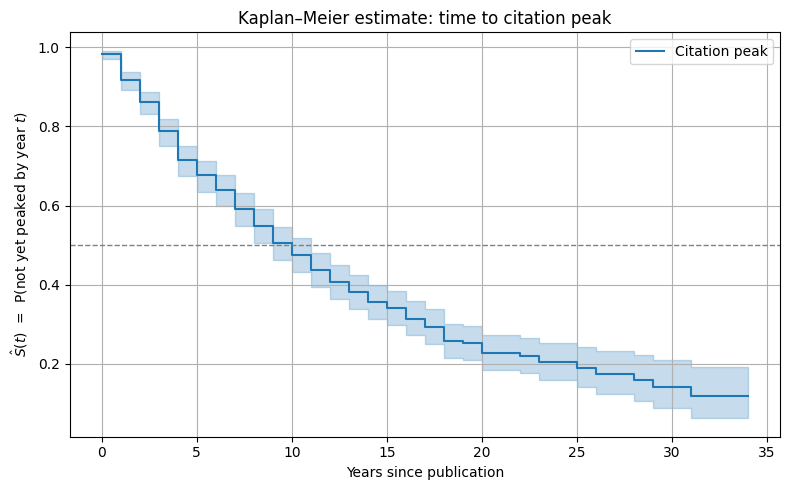

In [3]:
kmf = KaplanMeierFitter()
kmf.fit(durations=df["peak_age"], event_observed=df["peaked"], label="Citation peak")

censoring_rate = 1 - df["peaked"].mean()
print(f"N papers: {len(df)}")
print(f"Censoring rate (not yet peaked): {censoring_rate:.1%}")

ax = kmf.plot_survival_function(ci_show=True)
ax.set_xlabel("Years since publication")
ax.set_ylabel(r"$\hat{S}(t)$  =  P(not yet peaked by year $t$)")
ax.set_title("Kaplan–Meier estimate: time to citation peak")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()


### 1.6 Quantiles of peak age

In [4]:
# --- Convenience: built-in lifelines quantile lookups ---
median_peak_age = kmf.median_survival_time_
ci_median = kmf.confidence_interval_survival_function_

print(f"Median peak age (t_0.5): {median_peak_age:.2f} years")

quantile_levels = [0.25, 0.50, 0.75]
# lifelines wants 1-p as the "percentile" of S(t); .values.ravel() flattens its (n,1) DataFrame output
quantile_ages = kmf.percentile(1 - np.array(quantile_levels)).values.ravel()

quantile_table = pd.DataFrame({
    "quantile (p)": quantile_levels,
    "peak_age (years)": quantile_ages
})
quantile_table


Median peak age (t_0.5): 10.00 years


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(


,quantile (p),peak_age (years)
0,0.25,4.0
1,0.50,10.0
2,0.75,20.0


### 1.7 Is a median peak age of ten years believable?

The estimate in §1.6 says a typical FSR paper does not reach its best citation year until a decade after publication, with an interquartile range of 4–20 years. Ke, Ferrara, Radicchi and Flammini (2015) describe the usual pattern in science as a peak a *few* years out. A ten-year median is far enough from that to need interrogating before it goes in front of the client: either FSR really is slow, or the estimator is measuring something other than ageing.

Three mechanisms could inflate the median, and all three are testable here.

**1. Censoring.** The 39.0% censoring rate is high, and censored observations are exactly the ones that hold $\hat S(t)$ up. But censoring is not spread evenly across the sample: it is almost entirely one kind of paper.

**2. Sparsity.** The median FSR paper has 3 citations in the OpenAlex annual series (4 in the Scopus `cited_by` field). An annual series that sums to 2 or 3 has an argmax determined by where one or two individual citations happened to land, which is closer to a coin flip than to a measurement of ageing. If most of the *observed* peaks come from papers like that, the KM curve is being driven by noise.

**3. Ties.** `np.argmax` returns the *first* maximum, so a paper whose best years are 3 and 14 is recorded as peaking at 3. This one runs the wrong way for our concern: tie-breaking on the first maximum biases peak ages **downward**, so it cannot explain a median that is too late. It is worth quantifying anyway, because it tells us how often the peak year is even well defined.

In [5]:
# Per-paper annual citation vectors (ages 0..current_age, missing years = 0).
# Reused throughout 1.7-1.11, so build it once.
d1 = df.copy()
series = {r.doi: np.array([annual_lookup.get((r.doi, a), 0) for a in range(r.current_age + 1)], float)
          for r in d1.itertuples()}
d1["total_cites"] = d1["doi"].map(lambda k: series[k].sum())
d1["peak_height"] = d1["doi"].map(lambda k: series[k].max())
d1["n_tied_max"]  = d1["doi"].map(lambda k: int((series[k] == series[k].max()).sum()))

n_cens = int((d1["peaked"] == 0).sum())
n_cens_zero = int(((d1["peaked"] == 0) & (d1["total_cites"] == 0)).sum())
print(f"Censored papers: {n_cens} of {len(d1)}")
print(f"  ... of which never cited at all: {n_cens_zero} ({n_cens_zero/n_cens:.0%} of the censoring)")
print(f"  ... median censoring time for never-cited papers: {d1.loc[d1.total_cites==0,'current_age'].median():.0f} years\n")

obs = d1[d1["peaked"] == 1]
print(f"Observed peaks: {len(obs)}. How much data is the argmax actually based on?")
for thr in [1, 2, 5, 10]:
    share = (obs["total_cites"] <= thr).mean()
    print(f"  peaks from papers with <= {thr:2d} lifetime citations : {share:6.1%}")
print(f"  peaks where the annual maximum is a single citation : {(obs['peak_height'] == 1).mean():6.1%}")
print(f"  peaks where two or more years tie at the maximum    : {(obs['n_tied_max'] > 1).mean():6.1%}")

Censored papers: 240 of 616
  ... of which never cited at all: 203 (85% of the censoring)
  ... median censoring time for never-cited papers: 12 years

Observed peaks: 376. How much data is the argmax actually based on?
  peaks from papers with <=  1 lifetime citations :  11.7%
  peaks from papers with <=  2 lifetime citations :  20.5%
  peaks from papers with <=  5 lifetime citations :  41.2%
  peaks from papers with <= 10 lifetime citations :  62.0%
  peaks where the annual maximum is a single citation :  32.4%
  peaks where two or more years tie at the maximum    :  44.1%


Both worries are real. 203 of the 240 censored papers (85% of all the censoring) are papers that have never been cited once; they sit in the risk set for a median of 12 years contributing nothing but delay. And 41.2% of the *observed* peaks come from papers with five or fewer lifetime citations, with a third of them having an annual maximum of exactly one citation. For those papers "the peak year" is just "the year the citation arrived".

So the censoring rate and the sparsity are not separate problems, they are the same problem seen twice: FSR's citation counts are low, which simultaneously produces many never-cited papers (censoring) and many noisy argmaxes (sparsity). The question is whether stripping both out changes the answer. Below we refit KM on progressively better-cited subsets. This is a **robustness check, not a replacement model**: excluding uncited papers would bias the headline estimate, because "not yet peaked" is a legitimate state and those papers belong in the risk set.

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/

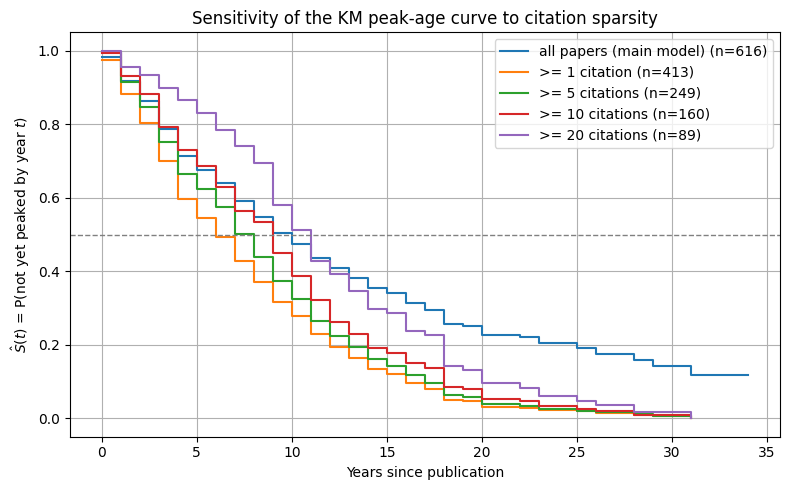

Mature, well-cited subsample (age >= 20 and >= 10 citations): n = 111, censoring 0.9%
  observed peak age: median 10, IQR 6-14.5 years


,subset,N,censored,q25,median,q75
0,all papers (main model),616,39.0%,4.0,10.0,20.0
1,>= 1 citation,413,9.0%,3.0,6.0,11.0
2,>= 5 citations,249,2.8%,4.0,8.0,12.0
3,>= 10 citations,160,3.1%,4.0,9.0,13.0
4,>= 20 citations,89,4.5%,7.0,11.0,16.0


In [6]:
from lifelines import KaplanMeierFitter

def km_quantiles(frame, dur="peak_age", ev="peaked"):
    k = KaplanMeierFitter().fit(frame[dur], frame[ev])
    q25, q50, q75 = k.percentile(1 - np.array([0.25, 0.50, 0.75])).values.ravel()
    return k, q25, q50, q75

rows = []
fig, ax = plt.subplots()
for thr, lab in [(0, "all papers (main model)"), (1, ">= 1 citation"),
                 (5, ">= 5 citations"), (10, ">= 10 citations"), (20, ">= 20 citations")]:
    sub = d1[d1["total_cites"] >= thr]
    k, q25, q50, q75 = km_quantiles(sub)
    rows.append({"subset": lab, "N": len(sub), "censored": 1 - sub["peaked"].mean(),
                 "q25": q25, "median": q50, "q75": q75})
    k.plot_survival_function(ax=ax, ci_show=False, label=f"{lab} (n={len(sub)})")

ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Years since publication")
ax.set_ylabel(r"$\hat S(t)$ = P(not yet peaked by year $t$)")
ax.set_title("Sensitivity of the KM peak-age curve to citation sparsity")
plt.tight_layout(); plt.show()

# The cleanest possible subsample: old enough that censoring is nearly absent,
# and cited enough that the annual maximum is not a coin flip.
mature = d1[(d1["current_age"] >= 20) & (d1["total_cites"] >= 10)]
print(f"Mature, well-cited subsample (age >= 20 and >= 10 citations): n = {len(mature)}, "
      f"censoring {1 - mature['peaked'].mean():.1%}")
print("  observed peak age: median {:.0f}, IQR {:.0f}-{:.1f} years".format(
    mature["peak_age"].median(), *np.percentile(mature["peak_age"], [25, 75])))

robust = pd.DataFrame(rows)
robust["censored"] = robust["censored"].map(lambda v: f"{v:.1%}")
robust

The headline number survives. Dropping the never-cited papers collapses the censoring rate from 39.0% to 9.0% and pulls the median down to 6 years, but that subset is still 20% papers with one or two citations. As the citation floor rises and the argmax becomes meaningful, the median climbs back: 8 years at five or more citations, 9 at ten or more, 11 at twenty or more. The cleanest subsample available is the 111 papers that are at least 20 years old *and* have at least 10 citations, where censoring is 0.9% and the annual series has real structure. Their observed median peak age is 10 years, IQR 6–14.5, which lands on the same answer as the full KM fit.

That coincidence is worth stating plainly, because it means the 10-year median is not a censoring artefact and not a sparsity artefact. The honest caveat is about the *spread*, not the centre: the 4–20 year interquartile range in §1.6 is much wider than the 6–14.5 range in the clean subsample, and most of that extra width is the noise contributed by one- and two-citation papers. Report the median with confidence; treat the quartiles as an upper bound on the true dispersion.

One caveat that cannot be tested away. Peak age and observation window are mechanically linked: a paper published in 2015 cannot be recorded as peaking at age 20. KM handles this correctly by censoring, but every quantile beyond about 15 years is estimated off the pre-2010 cohort alone, and should be read as a statement about those cohorts.

### 1.8 Fitting an ageing curve, and why FSR peaks so late

The brief asks for a simple ageing curve. The obvious approach, averaging annual citations across all papers at each age, does not work here, and the reason it fails is itself informative. The panel is unbalanced: age 25 is only observed for papers published in 2000 or earlier, so the "age profile" partly measures which cohort is still in the sample. We therefore restrict to a **cohort-balanced panel**, the 141 papers old enough to be observed over the full 0–25 window, so the same papers contribute to every point on the curve.

Even balanced, the raw mean profile is dominated by a handful of papers. FSR's citation distribution is extremely concentrated, so a mean is close to a description of its single best paper. We report two versions:

- **Cohort mean with the top 5% removed**, which describes the ordinary paper in citations-per-year units.
- **Mean within-paper share**, where every paper is first divided by its own lifetime total so each contributes equally regardless of size. This is the "typical shape" rather than the "typical level".

To both we fit a log-normal ageing curve, the standard functional form for citation ageing:

$$
c(t) \;=\; \frac{A}{(t+1)\,\sigma\sqrt{2\pi}} \exp\!\left( -\frac{\big(\ln(t+1) - \mu\big)^2}{2\sigma^2} \right)
$$

shifted by one year so that $t = 0$ (the publication year) is in the domain. The fitted peak is the mode, $\exp(\mu - \sigma^2) - 1$ years after publication.

Balanced cohort: n = 141 papers published 1991-2000, observed over ages 0-25
Citation concentration across all 616 FSR papers: top paper 16.4%, top 10 45.1%, top 5% 64.5% of all citations
cohort mean, top 5% removed   : mu=3.555  sigma=0.991  peak (mode) =  12.1 yr  R2=0.75
mean within-paper share       : mu=3.613  sigma=1.166  peak (mode) =   8.5 yr  R2=0.47


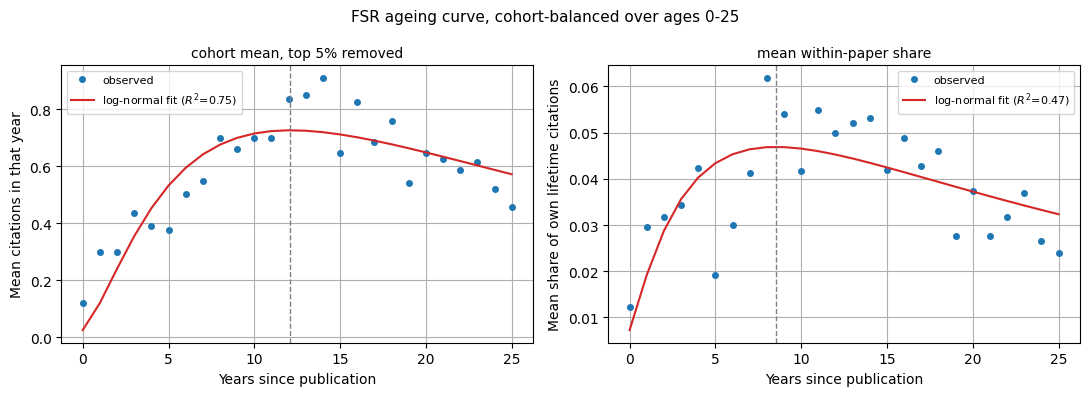


Untrimmed cohort mean profile (blockbusters included), ages 0-25:
[0.13 0.34 0.37 0.51 0.45 0.53 0.65 0.8  1.07 1.02 1.08 1.18 1.48 1.5
 1.61 1.48 1.87 1.82 1.83 1.61 1.74 2.06 2.35 2.52 2.34 2.6 ]
argmax of the untrimmed mean profile: age 25 (it never turns over)


In [7]:
from scipy.optimize import curve_fit

# Cohort-balanced panel: every paper old enough to be observed over the full 0..25 window.
BAL = 25
bal = d1[d1["current_age"] >= BAL]
M = np.vstack([series[k][:BAL + 1] for k in bal["doi"]])
tot = M.sum(axis=1)

print(f"Balanced cohort: n = {len(bal)} papers published {bal.pub_year.min()}-{bal.pub_year.max()}, "
      f"observed over ages 0-{BAL}")
share_top = np.sort(d1['total_cites'])[::-1]
print(f"Citation concentration across all {len(d1)} FSR papers: "
      f"top paper {share_top[0]/share_top.sum():.1%}, top 10 {share_top[:10].sum()/share_top.sum():.1%}, "
      f"top 5% {share_top[:31].sum()/share_top.sum():.1%} of all citations")

trimmed = M[tot < np.percentile(tot, 95)].mean(axis=0)   # cohort mean, blockbusters removed
shares  = (M[tot > 0] / tot[tot > 0][:, None]).mean(axis=0)  # mean within-paper share of own total
ages = np.arange(BAL + 1, dtype=float)

def lognormal_ageing(t, A, mu, sigma):
    x = t + 1.0
    return A / (x * sigma * np.sqrt(2 * np.pi)) * np.exp(-(np.log(x) - mu) ** 2 / (2 * sigma ** 2))

fits = {}
for name, y in [("cohort mean, top 5% removed", trimmed), ("mean within-paper share", shares)]:
    p, _ = curve_fit(lognormal_ageing, ages, y, p0=[1.0, 2.5, 1.0], maxfev=200000)
    A, mu, sigma = p
    pred = lognormal_ageing(ages, *p)
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    fits[name] = (p, r2)
    print(f"{name:30s}: mu={mu:.3f}  sigma={sigma:.3f}  peak (mode) = {np.exp(mu - sigma**2) - 1:5.1f} yr  R2={r2:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, (name, y) in zip(axes, [("cohort mean, top 5% removed", trimmed), ("mean within-paper share", shares)]):
    p, r2 = fits[name]
    ax.plot(ages, y, "o", ms=4, color="#1f77b4", label="observed")
    ax.plot(ages, lognormal_ageing(ages, *p), "-", color="#d62728",
            label=f"log-normal fit ($R^2$={r2:.2f})")
    ax.axvline(np.exp(p[1] - p[2] ** 2) - 1, color="gray", ls="--", lw=1)
    ax.set_title(name, fontsize=10); ax.set_xlabel("Years since publication"); ax.legend(fontsize=8)
axes[0].set_ylabel("Mean citations in that year")
axes[1].set_ylabel("Mean share of own lifetime citations")
plt.suptitle("FSR ageing curve, cohort-balanced over ages 0-25", fontsize=11)
plt.tight_layout(); plt.show()

print("\nUntrimmed cohort mean profile (blockbusters included), ages 0-25:")
print(np.round(M.mean(axis=0), 2))
print(f"argmax of the untrimmed mean profile: age {M.mean(axis=0).argmax()} (it never turns over)")

The two fits bracket the KM answer: a peak at 12.1 years for the ordinary paper and 8.5 years for the typical shape, against a KM median of 10. Three different estimators built on different assumptions agreeing to within a few years is about as much corroboration as this sample can offer.

The $R^2$ of 0.47 on the share version is poor and should be reported as such. The within-paper share profile is bumpy because the underlying counts are small integers, and a smooth two-parameter curve cannot track that. The fit also extrapolates badly: with $\sigma \approx 1.17$ the implied log-normal median sits beyond 30 years, well outside the data. Use the fitted mode as a description of where the curve turns over inside the 0–25 window, and do not read anything into the tail.

The last line is the part to take seriously. The **untrimmed** balanced cohort mean never turns over at all: it is still climbing at age 25. That is not a peak-and-decline curve. FSR's aggregate citation stream is dominated by a small set of papers that are still accelerating a quarter-century after publication, and the top paper alone accounts for 16.4% of every citation the journal has received. The "rise, peak, decline" story from the literature describes FSR's ordinary papers, not FSR's important ones.

There is one more explanation to rule out. FSR papers published in the 1990s spent their later years inside a citing literature that was growing fast, so their annual counts could drift upward for reasons that have nothing to do with the paper. If so, the late peak is an artefact of field growth rather than a property of FSR research.

We can bound this. Estimate the growth rate of citations received per FSR paper-year at risk, deflate every paper's annual series by that index, then rerun the whole peak-detection and KM pipeline on the deflated series. Age, publication year and calendar year satisfy `age = calendar year - publication year` exactly, so age, cohort and period effects are not separately identified and this cannot be a clean decomposition. What it gives is a lower bound: the peak age that remains once *all* of the observed calendar-time growth is attributed to the field rather than to the papers.

In [8]:
# How fast did the citing literature grow? Citations received per FSR paper-year at risk.
panel = pd.DataFrame([(r.doi, r.pub_year + a, series[r.doi][a])
                      for r in d1.itertuples() for a in range(r.current_age + 1)],
                     columns=["doi", "cal_year", "c"])
intensity = panel.groupby("cal_year")["c"].mean()
fit_yrs = intensity.loc[2000:2023]
slope = np.polyfit(fit_yrs.index - 2000, np.log(fit_yrs.values), 1)[0]
GROWTH = float(np.exp(slope) - 1)
print(f"Citations per at-risk FSR paper-year grew {GROWTH:.1%} per year over 2000-2023 "
      f"({intensity.loc[2023]/intensity.loc[2000]:.1f}x in total).")
print(f"Indexing lag check: 2023 = {intensity.loc[2023]:.2f}, 2024 = {intensity.loc[2024]:.2f}, "
      f"2025 = {intensity.loc[2025]:.2f} citations per paper-year.")

# Deflate every paper's annual counts by the field-growth index, then redo the whole peak rule.
def deflated_peak(doi, pub_year, current_age):
    s = series[doi] / np.exp(slope * (pub_year + np.arange(current_age + 1) - 2000))
    if s.sum() == 0:
        return current_age, 0
    pa = int(np.argmax(s))
    return (pa, 1) if pa < current_age else (current_age, 0)

d1["peak_age_defl"], d1["peaked_defl"] = zip(*[deflated_peak(r.doi, r.pub_year, r.current_age)
                                               for r in d1.itertuples()])
cmp_rows = []
for thr, lab in [(0, "all papers"), (5, ">= 5 citations"), (10, ">= 10 citations"), (20, ">= 20 citations")]:
    sub = d1[d1["total_cites"] >= thr]
    _, _, raw_med, _ = km_quantiles(sub)
    _, _, def_med, _ = km_quantiles(sub, "peak_age_defl", "peaked_defl")
    cmp_rows.append({"subset": lab, "N": len(sub), "KM median, raw": raw_med,
                     "KM median, field-deflated": def_med})
print()
print(pd.DataFrame(cmp_rows).to_string(index=False))

# Is the peak moving earlier for newer cohorts? Compare on a common 0-15 window.
W = 15
common = d1[d1["current_age"] >= W].copy()
CM = np.vstack([series[k][:W + 1] for k in common["doi"]])
common["tot_w"], common["peak_w"] = CM.sum(axis=1), CM.argmax(axis=1)
cw = common[common["tot_w"] >= 10]
from scipy.stats import spearmanr
rho = spearmanr(cw["pub_year"], cw["peak_w"])
print(f"\nCommon 0-{W} year window, papers with >= 10 citations in it (n = {len(cw)}):")
print(cw.groupby(pd.cut(cw["pub_year"], [1990, 1997, 2003, 2010]), observed=True)["peak_w"]
        .agg(["size", "median", "mean"]).round(2).to_string())
print(f"Spearman(publication year, peak age) = {rho.correlation:.3f}, p = {rho.pvalue:.4f}")

Citations per at-risk FSR paper-year grew 5.9% per year over 2000-2023 (4.4x in total).
Indexing lag check: 2023 = 1.53, 2024 = 1.17, 2025 = 0.76 citations per paper-year.

         subset   N  KM median, raw  KM median, field-deflated
     all papers 616            10.0                        9.0
 >= 5 citations 249             8.0                        7.0
>= 10 citations 160             9.0                        7.0
>= 20 citations  89            11.0                        9.0

Common 0-15 year window, papers with >= 10 citations in it (n = 110):
              size  median   mean
pub_year                         
(1990, 1997]    17    11.0  10.00
(1997, 2003]    54     9.0   9.19
(2003, 2010]    39     6.0   6.67
Spearman(publication year, peak age) = -0.361, p = 0.0001


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/

Field growth is real but small as an explanation. Citations received per at-risk FSR paper-year grew 5.9% a year over 2000–2023, a 4.4-fold rise. Attributing all of that to the field and none to the papers moves the KM median from 10 years to 9 for the full sample, and from 9 to 7 for papers with at least ten citations. So growth in the citing literature buys back one or two years of the gap against the bibliometric literature. It does not explain a decade.

Two further notes on the data. The indexing lag check shows citation intensity falling from 1.53 per paper-year in 2023 to 1.17 in 2024 and 0.76 in 2025, which is very unlikely to be a real collapse and much more likely to be OpenAlex still back-filling recent citing works. Treating 2025 as the last complete year is therefore slightly optimistic: the final one or two years are undercounted, which makes an earlier year more likely to hold the maximum and so pushes measured peak ages *earlier*, not later. It works against the finding rather than for it.

The cohort comparison is the more interesting result, and it is the one the client should act on. Holding the observation window fixed at 0–15 years and looking only at papers with at least ten citations in that window, the median peak age falls from 11 years for the 1991–1997 cohort to 9 for 1998–2003 to 6 for 2004–2010. Spearman's $\rho$ between publication year and peak age is $-0.36$ ($p = 0.0001$, $n = 110$). Part of this is mechanical, since the recent cohort's late window overlaps the undercounted 2024–2025 years, but a drop of five years is larger than that artefact can account for. FSR's ageing is speeding up. The ten-year median is partly a legacy of the journal's 1990s output, and papers published today should be expected to peak nearer six years out.

### 1.9 Sleeping beauties, flashes in the pan, and the rest

The brief names three patterns. To classify papers into them we need a statistic that measures *when* a paper's citations arrive relative to its peak, and the standard one is the **beauty coefficient** of Ke et al. (2015). Let $c_t$ be citations in year $t$ after publication, $t_m$ the year of the maximum and $c_{t_m}$ that maximum. Draw the straight line from $(0, c_0)$ to $(t_m, c_{t_m})$ and measure how far the actual trajectory sits below it:

$$
B \;=\; \sum_{t=0}^{t_m} \frac{\dfrac{c_{t_m} - c_0}{t_m}\, t \;+\; c_0 \;-\; c_t}{\max(1,\, c_t)}
$$

A paper that climbs steadily along the line scores near zero. A paper that stays flat for years and then jumps scores high, because every early term contributes a large positive gap divided by a tiny denominator. The $\max(1, c_t)$ in the denominator stops zero-citation years dividing by zero. By convention $B = 0$ when $t_m = 0$, since there is no line to sit under.

The companion statistic is the **awakening time** $t_a$, the year in $[0, t_m]$ at maximum perpendicular distance from that same line:

$$
t_a \;=\; \operatorname*{arg\,max}_{0 \le t \le t_m} \; \frac{\big|\, (c_{t_m} - c_0)\, t \;-\; t_m\, c_t \;+\; t_m\, c_0 \,\big|}{\sqrt{(c_{t_m} - c_0)^2 + t_m^2}}
$$

which is where the trajectory bends away from dormancy.

**$B$ is meaningless on small counts.** A paper with four citations spread over twenty years will produce a large $B$ purely because its early years are zeros, and that tells us nothing about dormancy. We therefore restrict classification to papers with **at least 20 lifetime citations and at least 15 years of observation**. That is deliberately strict and it costs us most of the journal, but a classification computed on three citations would not be worth reporting.

**Calling a paper a sleeping beauty needs a benchmark, not a quota.** Taking "the top decile of $B$" would define 10% of papers as sleeping beauties by construction, which then makes any comparison against other literatures circular. Instead we use the ageing curve fitted in §1.8 as a **null model**. For each paper, simulate its actual citation count landing across its actual observation window according to the fitted log-normal ageing profile, scaled by the field-growth index so the null already contains the calendar-time effect from §1.8. Repeat 2,000 times, and ask where the paper's real $B$ falls in its own null distribution. The classification is then:

- **Sleeping beauty**: $B$ significantly higher than the null ($p < 0.05$), meaning the paper's citations arrived later than FSR's own ageing curve plus field growth would predict.
- **Flash in the pan**: not a sleeping beauty, and the share of citations in the first five years is significantly *above* null ($p < 0.05$), the peak is at age 5 or earlier, and the five years after the peak average no more than half the peak. Early rise and observed decline, both required.
- **Normal**: everything else.

In [9]:
def beauty_coefficient(c):
    """Ke et al. (2015) beauty coefficient B and awakening time t_a for one annual series."""
    t_m = int(np.argmax(c))
    c_m, c_0 = c[t_m], c[0]
    if t_m == 0:
        return 0.0, 0                       # peaks in year 0: no line to sit under, B := 0
    t = np.arange(t_m + 1)
    line = (c_m - c_0) / t_m * t + c_0
    B = float(np.sum((line - c[:t_m + 1]) / np.maximum(1.0, c[:t_m + 1])))
    dist = np.abs((c_m - c_0) * t - t_m * c[:t_m + 1] + t_m * c_0) / np.sqrt((c_m - c_0) ** 2 + t_m ** 2)
    return B, int(np.argmax(dist))

MIN_CITES, MIN_AGE = 20, 15
qual = d1[(d1["total_cites"] >= MIN_CITES) & (d1["current_age"] >= MIN_AGE)].copy()
print(f"Papers eligible for classification (>= {MIN_CITES} citations and >= {MIN_AGE} years old): "
      f"{len(qual)} of {len(d1)} ({len(qual)/len(d1):.1%})")

qual["B"], qual["t_a"] = zip(*[beauty_coefficient(series[k]) for k in qual["doi"]])
qual["t_m"] = [int(np.argmax(series[k])) for k in qual["doi"]]
qual["c_m"] = [series[k].max() for k in qual["doi"]]
qual["F5"] = [series[k][:5].sum() / series[k].sum() for k in qual["doi"]]
qual["post5"] = [series[k][int(np.argmax(series[k])) + 1:int(np.argmax(series[k])) + 6].mean()
                 / series[k].max() if len(series[k][int(np.argmax(series[k])) + 1:]) else np.nan
                 for k in qual["doi"]]

print(f"B: median {qual['B'].median():.1f}, 90th pct {qual['B'].quantile(0.9):.1f}, "
      f"max {qual['B'].max():.1f}; {(qual['B'] <= 1).mean():.1%} of papers have B <= 1")

# --- Null model: what B and early-share would this paper show if its citations landed
#     according to the fitted ageing curve, scaled by field growth? ---
MU, SIGMA = fits["mean within-paper share"][0][1], fits["mean within-paper share"][0][2]
rng = np.random.default_rng(7)
N_SIM = 2000

def null_pmf(L, pub_year):
    x = np.arange(L + 1.0) + 1.0
    p = 1 / (x * SIGMA * np.sqrt(2 * np.pi)) * np.exp(-(np.log(x) - MU) ** 2 / (2 * SIGMA ** 2))
    p = p * np.exp(slope * (pub_year + np.arange(L + 1.0) - 2000))
    return p / p.sum()

p_late, p_early = [], []
for r in qual.itertuples():
    s = series[r.doi]; N = int(s.sum()); L = len(s) - 1
    draws = rng.multinomial(N, null_pmf(L, r.pub_year), size=N_SIM).astype(float)
    B_null = np.array([beauty_coefficient(draws[j])[0] for j in range(N_SIM)])
    F5_null = draws[:, :5].sum(axis=1) / N
    p_late.append((B_null >= r.B).mean())
    p_early.append((F5_null >= r.F5).mean())
qual["p_late"], qual["p_early"] = p_late, p_early

is_sb = qual["p_late"] < 0.05
is_fp = (~is_sb) & (qual["p_early"] < 0.05) & (qual["t_m"] <= 5) & (qual["post5"] <= 0.5)
qual["trajectory"] = np.where(is_sb, "sleeping beauty", np.where(is_fp, "flash in the pan", "normal"))

summary = (qual.groupby("trajectory")
               .agg(n=("B", "size"), median_peak_age=("t_m", "median"),
                    median_awakening=("t_a", "median"), median_B=("B", "median"),
                    median_total_cites=("total_cites", "median"),
                    median_first5_share=("F5", "median"), median_pub_year=("pub_year", "median")))
summary["share_of_eligible"] = (summary["n"] / len(qual)).map("{:.1%}".format)
summary = summary.round(2)
summary

Papers eligible for classification (>= 20 citations and >= 15 years old): 78 of 616 (12.7%)
B: median 11.0, 90th pct 44.1, max 148.0; 5.1% of papers have B <= 1


,n,median_peak_age,median_awakening,median_B,median_total_cites,median_first5_share,median_pub_year,share_of_eligible
trajectory,,,,,,,,
flash in the pan,9,3.0,1.0,1.44,38.0,0.29,2004.0,11.5%
normal,57,10.0,9.0,10.10,36.0,0.08,2000.0,73.1%
sleeping beauty,12,20.0,17.0,52.94,196.5,0.02,1999.0,15.4%


The three classes separate cleanly on statistics that were not used to define them. Sleeping beauties peak at a median of 20 years with an awakening at 17 and take just 2% of their citations in the first five years. Normal papers peak at 10 with an awakening at 9 and take 8% early. Flashes peak at 3, awaken at 1, and take 29% of everything they will ever get in their first five years. The split is 15.4% / 73.1% / 11.5% of the 78 eligible papers.

The counts are small and the thresholds are choices, so these shares are indicative rather than precise. A sensitivity run without the field-growth term in the null reclassifies several borderline normal papers as sleeping beauties (25 rather than 12), which is exactly the ambiguity §1.8 warned about: the later a paper peaks, the harder it is to tell "this paper woke up" from "the citing literature got bigger". The 12 reported here is the conservative count.

In [10]:
titles = master_fsr.drop_duplicates("doi").set_index("doi")["title"]
qual["title"] = qual["doi"].map(titles)

exemplars = {}
for cls, key in [("sleeping beauty", "B"), ("flash in the pan", "F5"), ("normal", "total_cites")]:
    top = qual[qual["trajectory"] == cls].nlargest(3, key)
    exemplars[cls] = top
    print(f"--- {cls} ---")
    for r in top.itertuples():
        print(f"  {r.pub_year}  {int(r.total_cites):4d} cites  peak at age {r.t_m:2d}  "
              f"awakening {r.t_a:2d}  B={r.B:6.1f}  | {r.title[:70]}")
    print()

sb_cites = qual.loc[qual["trajectory"] == "sleeping beauty", "total_cites"].sum()
print(f"The {int((qual['trajectory']=='sleeping beauty').sum())} sleeping beauties are "
      f"{(qual['trajectory']=='sleeping beauty').sum()/len(d1):.1%} of all FSR papers but hold "
      f"{sb_cites/d1['total_cites'].sum():.1%} of every citation FSR has ever received.")
top10 = d1.nlargest(10, "total_cites")["doi"]
print("Of FSR's 10 most-cited papers, trajectory class:")
print(qual.set_index("doi").reindex(top10)["trajectory"].value_counts(dropna=False).to_string())

# Topic tilt: how often do the class's titles and keywords mention each theme, per paper?
kw = master_fsr.drop_duplicates("doi").set_index("doi")["author_keywords"].fillna("")
qual["text"] = (qual["title"].fillna("") + " " + qual["doi"].map(kw)).str.lower()
themes = ["literacy", "risk toleran", "retirement", "withdraw", "asset alloc"]
tilt = pd.DataFrame({th: qual.groupby("trajectory")["text"].apply(lambda s: s.str.count(th).mean())
                     for th in themes}).round(2)
print("\nMentions per paper in title + author keywords:")
print(tilt.to_string())

--- sleeping beauty ---
  1998  1747 cites  peak at age 25  awakening 19  B= 148.0  | An Analysis of Personal Financial Literacy Among College Students
  1992   129 cites  peak at age 28  awakening 24  B= 118.8  | An index of portfolio diversification
  1997    31 cites  peak at age 22  awakening 19  B=  89.8  | The Challenges and Opportunities of Student-Managed Investment Funds a

--- flash in the pan ---
  2007    24 cites  peak at age  1  awakening  0  B=   0.0  | Implications of principal, risk, and returns sharing across savings ve
  2004    25 cites  peak at age  4  awakening  3  B=   3.2  | Formulating retirement targets and the impact of time horizon on asset
  2008    47 cites  peak at age  1  awakening  0  B=   0.0  | Stochastic optimization of retirement portfolio asset allocations and 

--- normal ---
  2004   469 cites  peak at age 20  awakening 19  B=   3.1  | An Empirical Investigation of Personal Financial Risk Tolerance
  2007   269 cites  peak at age 10  awakening  9

This is the single most consequential result in Part 1. **Twelve papers, 1.9% of everything FSR has published, account for 40.3% of every citation the journal has ever received, and all twelve are late bloomers.** Six of FSR's ten most-cited papers are sleeping beauties. The flagship case is Chen and Volpe's 1998 *An Analysis of Personal Financial Literacy Among College Students*, which awoke at age 19, peaked at age 25 and has 1,747 citations in the OpenAlex series. *An index of portfolio diversification* (1992) awoke at 24 and peaked at 28.

The topic pattern is just as usable. Sleeping beauties are the financial-literacy and risk-tolerance papers: 0.33 mentions of "literacy" and 0.42 of "risk toleran" per paper, against 0.07 each for normal papers and essentially zero for flashes. Flashes are the retirement-withdrawal and asset-allocation papers: 1.11 mentions of "retirement", 0.44 of "withdraw" and 0.56 of "asset alloc" per paper, against 0.32, 0.00 and 0.11 for normal papers. That is a clean separation between work that defines a construct other researchers go on to measure, and work that answers a practitioner question well enough that nobody needs to cite it again.

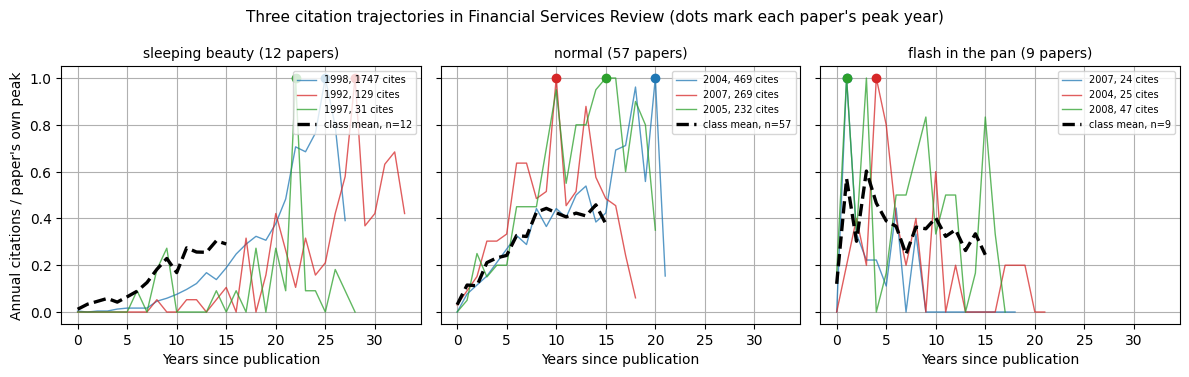

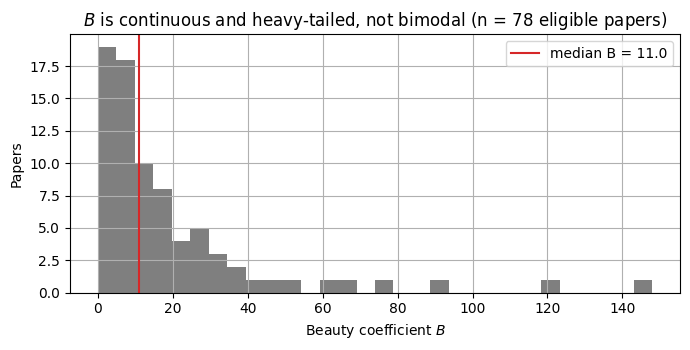

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
palette = ["#1f77b4", "#d62728", "#2ca02c"]
W_CMP = 15   # every eligible paper is at least 15 years old, so class means are comparable here
for ax, cls in zip(axes, ["sleeping beauty", "normal", "flash in the pan"]):
    for col, r in zip(palette, exemplars[cls].itertuples()):
        s = series[r.doi]
        ax.plot(np.arange(len(s)), s / s.max(), color=col, lw=1.0, alpha=0.75,
                label=f"{r.pub_year}, {int(r.total_cites)} cites")
        ax.plot(r.t_m, 1.0, "o", color=col, ms=6)
    mem = qual.loc[qual["trajectory"] == cls, "doi"]
    avg = np.vstack([series[k][:W_CMP + 1] / series[k].max() for k in mem]).mean(axis=0)
    ax.plot(np.arange(W_CMP + 1), avg, color="black", lw=2.4, ls="--",
            label=f"class mean, n={len(mem)}")
    ax.set_title(f"{cls} ({len(mem)} papers)", fontsize=10)
    ax.set_xlabel("Years since publication"); ax.legend(fontsize=7, loc="upper right")
axes[0].set_ylabel("Annual citations / paper's own peak")
plt.suptitle("Three citation trajectories in Financial Services Review "
             "(dots mark each paper's peak year)", fontsize=11)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(qual["B"], bins=30, color="#7f7f7f")
ax.axvline(qual["B"].median(), color="#d62728", lw=1.5,
           label=f"median B = {qual['B'].median():.1f}")
ax.set_xlabel("Beauty coefficient $B$"); ax.set_ylabel("Papers"); ax.legend()
ax.set_title(f"$B$ is continuous and heavy-tailed, not bimodal (n = {len(qual)} eligible papers)")
plt.tight_layout(); plt.show()

**How does FSR compare with science generally?** Ke et al. (2015) analysed roughly 22 million papers and found that $B$ is continuous and heavy-tailed with no natural cutoff, so sleeping beauties are the extreme end of a spectrum rather than a separate species. The histogram above reproduces that shape exactly: a dense mass near zero, a long thin tail, no second mode. Our null-model test does not contradict this. It identifies papers that are unusual relative to FSR's own ageing curve, not papers drawn from a distinct population.

Two things are different about FSR. First, **scale**. The extreme sleeping beauties Ke et al. single out have $B$ in the thousands; FSR's maximum is 148 and its median is 11. $B$ grows with the size of the peak, and FSR papers peak at single- or double-digit annual counts, so absolute $B$ thresholds from the large-scale literature do not transfer. This is why we used a simulated null rather than a published cutoff.

Second, and more important, **the mix is tilted**. In a large multidisciplinary sample the large majority of papers decline after their maximum within a few years, and delayed recognition is rare. In FSR the ordinary paper peaks at 10 years, the eligible pool contains more delayed-recognition cases than fast-fading ones (12 against 9), and the sleeping beauties are not a curiosity in the tail: they are where almost half the journal's citations live. The plausible reason is audience. FSR sits between an academic and a financial-planning-practitioner readership, and its most-cited work supplies measurement instruments (financial literacy scales, risk-tolerance questionnaires) that take years to be adopted, replicated and then cited at volume by a downstream literature that barely existed when the papers appeared.

One honest limitation: no paper published after 2010 can be classified, because the rule requires 15 years of observation. We can say FSR *produced* sleeping beauties; we cannot say from these data whether it still does. The cohort trend in §1.8 suggests the mix may be shifting towards faster-peaking papers.

### 1.10 How early can a paper's success fairly be judged?

The brief asks whether eventual high-hitters can be spotted early, and the classification above makes clear why it matters: if FSR's most valuable papers are the ones that take twenty years, any short evaluation window will systematically undervalue exactly the work the journal most wants to attract.

We measure this two ways, on papers old enough to have a long observed record.

**Rank agreement.** For each evaluation age $k = 1, \dots, 10$, compute Spearman's $\rho$ between citations accrued by age $k$ and the paper's eventual total. That correlation is mechanically inflated, because the citations counted at age $k$ are themselves part of the total. We therefore also report $\rho$ between citations by age $k$ and citations received **after** age $k$, which shares no terms and is the honest measure of predictive content.

**Capture rate.** Of the papers that end up in the top decile by eventual total, what share were already in the top decile at age $k$? This is what an editorial team actually does: pick the apparent winners early and see how many turn out to be real. With equal-sized deciles the false-alarm rate is the complement of the capture rate.

Both are computed on a 20-year horizon (239 papers published up to 2005) and a 15-year horizon (339 papers published up to 2010), so "eventual total" means the same length of exposure for every paper in a given panel.

20-year horizon: 239 papers (published <= 2005); top decile = >= 39 citations by age 20
15-year horizon: 339 papers (published <= 2010); top decile = >= 27 citations by age 15
  20-year window (n=239): 3.3% of the total is in by age 2, 11.2% by age 5; half of it has not arrived until age 13.
  25-year window (n=141): 2.4% of the total is in by age 2, 6.7% by age 5; half of it has not arrived until age 17.


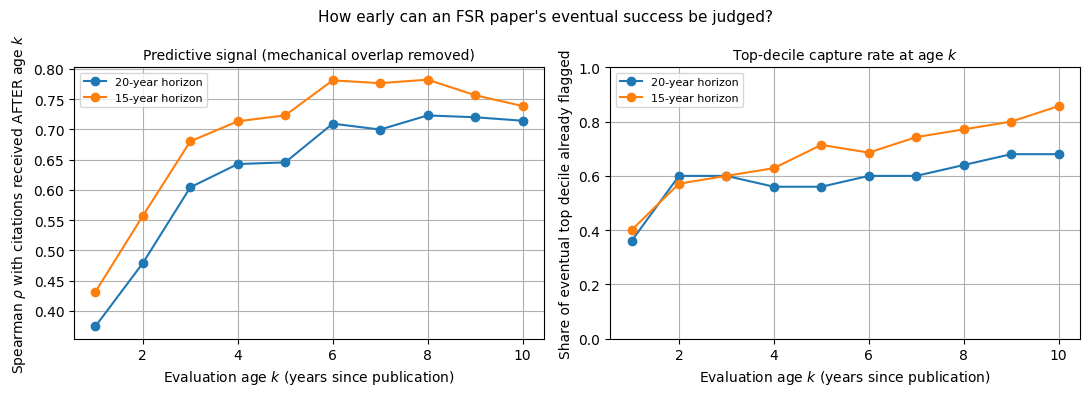


20-year horizon:
 age k  rho(by age k, eventual total)  rho(by age k, citations after k)  top-decile capture  % of eventual total in hand
     1                          0.419                             0.374                0.36                        0.017
     2                          0.547                             0.479                0.60                        0.033
     3                          0.679                             0.604                0.60                        0.057
     4                          0.734                             0.643                0.56                        0.083
     5                          0.755                             0.646                0.56                        0.112
     6                          0.826                             0.710                0.60                        0.148
     7                          0.842                             0.700                0.60                        0.187
     8        

In [12]:
def early_signal(horizon):
    """For papers old enough to be followed for `horizon` years, how well does the citation
    count at age k order papers on their eventual horizon-year total?"""
    sub = d1[d1["current_age"] >= horizon]
    M = np.vstack([series[k][:horizon + 1] for k in sub["doi"]])
    total, cum = M.sum(axis=1), M.cumsum(axis=1)
    top = total >= np.percentile(total, 90)
    out = []
    for k in range(1, 11):
        future = total - cum[:, k]
        flagged = cum[:, k] >= np.percentile(cum[:, k], 90)
        out.append({"age k": k,
                    "rho(by age k, eventual total)": spearmanr(cum[:, k], total).correlation,
                    "rho(by age k, citations after k)": spearmanr(cum[:, k], future).correlation,
                    "top-decile capture": (flagged & top).sum() / top.sum(),
                    "% of eventual total in hand": cum[:, k].sum() / total.sum()})
    return len(sub), int(np.percentile(total, 90)), pd.DataFrame(out)

n20, cut20, tab20 = early_signal(20)
n15, cut15, tab15 = early_signal(15)
print(f"20-year horizon: {n20} papers (published <= 2005); top decile = >= {cut20} citations by age 20")
print(f"15-year horizon: {n15} papers (published <= 2010); top decile = >= {cut15} citations by age 15")

# How long until half of a cohort's citations have actually arrived?
for H in [20, 25]:
    sub = d1[d1["current_age"] >= H]
    curve = np.vstack([series[k][:H + 1] for k in sub["doi"]])
    cum_share = curve.sum(axis=0).cumsum() / curve.sum()
    print(f"  {H}-year window (n={len(sub)}): {cum_share[2]:.1%} of the total is in by age 2, "
          f"{cum_share[5]:.1%} by age 5; half of it has not arrived until age {int(np.searchsorted(cum_share, 0.5))}.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for tab, lab, col in [(tab20, "20-year horizon", "#1f77b4"), (tab15, "15-year horizon", "#ff7f0e")]:
    axes[0].plot(tab["age k"], tab["rho(by age k, citations after k)"], "o-", color=col, label=lab)
    axes[1].plot(tab["age k"], tab["top-decile capture"], "o-", color=col, label=lab)
axes[0].set_ylabel("Spearman $\\rho$ with citations received AFTER age $k$")
axes[0].set_title("Predictive signal (mechanical overlap removed)", fontsize=10)
axes[1].set_ylabel("Share of eventual top decile already flagged")
axes[1].set_title("Top-decile capture rate at age $k$", fontsize=10)
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.set_xlabel("Evaluation age $k$ (years since publication)"); ax.legend(fontsize=8)
plt.suptitle("How early can an FSR paper's eventual success be judged?", fontsize=11)
plt.tight_layout(); plt.show()

print("\n20-year horizon:")
print(tab20.round(3).to_string(index=False))

The answer is more encouraging than the peak timing suggests, with one sharp limit.

**The early signal saturates fast.** On the 20-year horizon the honest correlation, between citations by age $k$ and citations received afterwards, rises from 0.37 at age 1 to 0.60 at age 3 and 0.65 at age 5, then flattens: 0.71 at age 6 and 0.71 at age 10. Waiting from year 5 to year 10 buys about 0.07 of extra rank correlation. Waiting from year 6 to year 10 buys essentially nothing. Whatever an FSR paper's early citations are going to tell us, they have told us by roughly year 6.

**But the ceiling is low.** The plateau sits at $\rho \approx 0.71$, not 0.95. Capture rates say the same thing in blunter terms: 60% of the eventual top decile is already flagged at age 3, and still only 68% at age 10. A three-year window identifies six of every ten winners; a ten-year window identifies seven. The extra seven years of waiting convert one additional paper in ten from a miss to a hit. That is a poor return on a seven-year delay.

**Almost nothing has happened by the time the rankings look.** Only 3.3% of a paper's 20-year citation total has arrived by age 2, the window a two-year impact factor uses, and 11.2% by age 5. Half of it has not arrived until age 13. On a 25-year window the figures are 2.4%, 6.7% and age 17.

The 15-year panel shows higher numbers throughout (capture of 71% at age 5, 86% at age 10) for a mechanical reason worth naming: over a shorter horizon there is less future left to be wrong about, so early counts look more predictive. The 20-year figures are the conservative ones.

In [13]:
# Who does an early evaluation window actually miss? Score the 20-year-horizon sample
# at age 5 and at age 20, then look at the misses by trajectory class.
H = 20
h20 = d1[d1["current_age"] >= H].copy()
HM = np.vstack([series[k][:H + 1] for k in h20["doi"]])
h20["by_age5"], h20["by_age20"] = HM[:, :6].sum(axis=1), HM.sum(axis=1)
h20["flag5"] = h20["by_age5"] >= np.percentile(h20["by_age5"], 90)
h20["top20"] = h20["by_age20"] >= np.percentile(h20["by_age20"], 90)
h20 = h20.merge(qual[["doi", "trajectory"]], on="doi", how="left")
h20["trajectory"] = h20["trajectory"].fillna("too few citations to classify")

missed = h20[h20["top20"] & ~h20["flag5"]]
false_alarm = h20[h20["flag5"] & ~h20["top20"]]
print(f"Of {int(h20['top20'].sum())} papers in the eventual top decile at 20 years, "
      f"{len(missed)} were not flagged at age 5.")
print("  their trajectory classes:", missed["trajectory"].value_counts().to_dict())
print(f"Of {int(h20['flag5'].sum())} papers flagged at age 5, {len(false_alarm)} dropped out of the "
      f"top decile by year 20.")
print("  their trajectory classes:", false_alarm["trajectory"].value_counts().to_dict())

sb = h20[h20["trajectory"] == "sleeping beauty"]
print(f"\nSleeping beauties in this horizon-20 sample: {len(sb)}; "
      f"{int(sb['flag5'].sum())} were in the top decile at age 5, "
      f"{int(sb['top20'].sum())} are in it at age 20.")
print(f"Median citations by age 5 for a sleeping beauty: {sb['by_age5'].median():.0f}; "
      f"for the rest of the sample: {h20.loc[h20['trajectory'] != 'sleeping beauty', 'by_age5'].median():.0f}")

Of 25 papers in the eventual top decile at 20 years, 11 were not flagged at age 5.
  their trajectory classes: {'normal': 9, 'sleeping beauty': 2}
Of 24 papers flagged at age 5, 10 dropped out of the top decile by year 20.
  their trajectory classes: {'normal': 6, 'flash in the pan': 3, 'too few citations to classify': 1}

Sleeping beauties in this horizon-20 sample: 10; 6 were in the top decile at age 5, 8 are in it at age 20.
Median citations by age 5 for a sleeping beauty: 8; for the rest of the sample: 1


This last check produced a result we did not expect, and it changes the recommendation.

Of the 25 papers in the eventual top decile at 20 years, 11 were invisible at age 5. But only 2 of those 11 are sleeping beauties; 9 are ordinary papers that simply started slowly. And of the 10 sleeping beauties in this panel, 6 were *already* in the top decile by age 5, with a median of 8 citations by then against 1 for everyone else.

So FSR's sleeping beauties are not dormant in the ordinary sense. A high $B$ here means "kept growing for two decades", not "went unnoticed and was rediscovered". These papers were visibly above average early; what was unforecastable was how far they would go, not whether they were any good. Chen and Volpe (1998) is the clearest case: it did not lie unread, it kept compounding.

The failure mode at age 5 is the other direction. Of the 24 papers flagged as top-decile at age 5, 10 fell out by year 20, and 3 of those 10 are flashes in the pan, papers whose early burst was the whole story. Early evaluation in FSR is not mainly at risk of missing the great papers. It is at risk of promoting the merely fast ones.

### 1.11 What this means for the Academy of Financial Services

**Judge papers at five years, not two, and not ten.** The predictive signal in early citations plateaus at about age 6 ($\rho \approx 0.71$ against future citations, up from 0.65 at age 5 and unchanged through age 10). A five-year assessment window already identifies 56–71% of eventual top-decile papers depending on the horizon used, and waiting a further five years raises that to 68%. A two-year window, by contrast, sees only 3.3% of a paper's eventual citations and is close to useless. Five years is where the information is; anything longer is paying a lot of delay for one extra winner in ten.

**Apply a haircut to anything that peaks in year 1 or 2.** The main error at five years is not missing greatness, it is mistaking speed for it: 10 of 24 age-5 flags dropped out of the top decile by year 20, and 3 of those were flashes in the pan. Flashes are recognisable by topic as well as by shape, concentrating in retirement-withdrawal and asset-allocation work (1.11 mentions of "retirement" and 0.44 of "withdraw" per paper, against 0.32 and 0.00 for normal papers). Practitioner-facing prescriptive papers earn their citations immediately and then stop. They are valuable to FSR's readership, but they should not be the template for what the journal commissions if the goal is citation growth.

**Commission instruments, not answers.** All six of FSR's ten most-cited papers that are sleeping beauties, and the whole 40.3% of the journal's citations held by those 12 papers, come from work that gave a downstream literature something to measure with: financial literacy scales, risk-tolerance instruments, diversification indices. The topic signature is unambiguous ("literacy" 0.33 and "risk toleran" 0.42 mentions per paper in the sleeping-beauty class, against 0.07 each among normal papers). A single paper of this type is worth more to FSR's citation stock than several hundred ordinary ones: Chen and Volpe (1998) alone is 16.4% of every citation the journal has ever received.

**Expect any editorial intervention to take five to ten years to move the rankings.** CABS, ABDC and Cabells assessments key off citation windows that are short relative to how FSR papers actually age. Half of a paper's 20-year citations have not arrived by age 13, and only 11.2% are in by age 5. A change of editorial policy made today affects papers published in two years, which will have accumulated roughly a tenth of their eventual citations by 2032. Any business case for changing what FSR publishes has to be argued on that timescale, and the journal should resist being judged on two-year metrics that capture 3% of its output's value.

**One piece of good news in the trend.** The gap is closing. On a fixed 0–15 year window, median peak age fell from 11 years for 1991–1997 papers to 6 years for 2004–2010 papers (Spearman $\rho = -0.36$, $p = 0.0001$). FSR's citations are arriving earlier than they used to, which makes the journal less disadvantaged by short evaluation windows than the headline 10-year median implies. It also means the 10-year figure should be quoted as a description of FSR's back catalogue, with roughly 6 years the better expectation for what the journal publishes now.

**What we cannot tell the client.** Nothing published after 2010 can be classified into a trajectory, so we cannot say whether FSR is still producing sleeping beauties. The peak-age estimate rests on annual series that are sparse for most papers, and while the median survives every robustness check we ran, the quartiles do not. And because age, publication year and calendar year are exactly collinear, no amount of modelling can fully separate "FSR papers age slowly" from "the citing literature grew". Deflating by the observed 5.9% annual growth is the strongest correction available and it moves the median by only one to two years, so the conclusion holds, but it is a bound rather than a decomposition.

# Question D, part 2: which papers become "high hitters"?

**Question:** Which paper-level factors are associated with higher total citation counts, once we account for the fact that older papers have simply had more time to accrue them?

**Approach:** a Negative Binomial regression of total citations on paper-level covariates, with publication age entered as an **offset**, i.e. we model the citation *rate per year of exposure*, not raw totals, so a coefficient reflects "this variable shifts citations per year," not "this variable correlates with being an old paper."


## 2.1 Model

Citation counts are non-negative integers, over-dispersed relative to a Poisson (a small number of papers get disproportionately many citations, the "high hitters" the question asks about), so Negative Binomial is the standard choice over plain Poisson.

For paper $i$, let $Y_i$ be total citations, $\text{age}_i$ years since publication, and $\mathbf{x}_i$ the paper-level covariates (author count, page length, etc.):

$$
Y_i \sim \text{NegBin}(\mu_i, \alpha)
$$

$$
\log(\mu_i) \;=\; \underbrace{\log(\text{age}_i)}_{\text{offset}} \;+\; \beta_0 + \boldsymbol{\beta}^\top \mathbf{x}_i
$$

Equivalently:

$$
\mathbb{E}[Y_i \mid \mathbf{x}_i] \;=\; \text{age}_i \cdot \exp(\beta_0 + \boldsymbol{\beta}^\top \mathbf{x}_i), \qquad \text{Var}(Y_i) = \mu_i + \alpha \mu_i^2
$$

An **offset** is a covariate whose coefficient is fixed at exactly 1, rather than estimated, so $\log(\text{age}_i)$ is *forced* into the linear predictor with coefficient 1, which is the same as saying "expected total citations scale linearly with age," and everything else in $\mathbf{x}_i$ is then interpreted as shifting the **citation rate per year**, not the raw total.

Each $\exp(\beta_j)$ is an **incidence rate ratio (IRR)**: multiply the yearly citation rate by $\exp(\beta_j)$ for a one-unit increase in $x_j$, holding age and everything else fixed.

### A check the offset assumption needs before we trust it

Forcing the age coefficient to exactly 1 assumes citations accrue *linearly* with age, since one extra year always buys the same number of extra citations, no matter the paper's age. That's a strong assumption, and it's directly in tension with the peak-and-decline shape found in Part 1 of this question (citations rise, peak, then decline, not a straight line). So before committing to the offset, we fit `log(age)` as a **free** covariate in a second model and check whether its estimated coefficient actually comes out close to 1. If it does, the offset is a reasonable simplification for this sample; if it doesn't, the offset version's other coefficients should be treated cautiously.


In [14]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import warnings

# statsmodels' NegativeBinomial likelihood throws a benign divide-by-zero warning
# at endog=0 rows during internal log() calls; it doesn't affect the fitted result.
warnings.filterwarnings("ignore", category=RuntimeWarning)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


## 2.2 Data & feature engineering

Source: `master_dataset.csv`, filtered to Financial Services Review (it also contains two other journals, see Part 1).

None of the covariates below exist as ready-made columns; they're derived from the raw fields:

| Feature | Derivation |
|---|---|
| `n_authors` | count of `;`-separated entries in `authors_id` |
| `n_affiliations` | count of `;`-separated entries in `affiliations` |
| `n_keywords` | count of `;`-separated entries in `author_keywords` (0 if missing) |
| `page_length` | `page_end - page_start` |
| `abstract_length` | word count of `abstract` |
| `pub_year_c` | `year`, mean-centred, controlling for calendar-era effects (see Part 1: the citing literature grew ~7.5x over the sample period, independent of paper age) |
| `age` | years since publication as of the last complete data year |

`document_type` was checked and dropped, since every FSR paper in this dataset is coded `"Article"`, so it carries no information.

Rows with missing `page_start`/`page_end` (5 papers) or `cited_by` are dropped, since those can't be used to build `page_length` or the outcome.


In [15]:
LAST_COMPLETE_YEAR = 2025

master = pd.read_csv("../data/master_dataset.csv")
fsr = master[master["source_title"] == "Financial Services Review"].copy()

fsr["n_authors"]       = fsr["authors_id"].str.split(";").str.len()
fsr["n_affiliations"]  = fsr["affiliations"].fillna("").str.split(";").str.len()
fsr["n_keywords"]      = fsr["author_keywords"].fillna("").apply(lambda s: len(s.split(";")) if s else 0)
fsr["page_length"]     = fsr["page_end"] - fsr["page_start"]
fsr["abstract_length"] = fsr["abstract"].fillna("").str.split().str.len()
fsr["age"]             = LAST_COMPLETE_YEAR - fsr["year"]
fsr["pub_year_c"]      = fsr["year"] - fsr["year"].mean()

fsr = fsr[fsr["age"] > 0].dropna(subset=["cited_by", "page_length"]).copy()
fsr["log_age"] = np.log(fsr["age"])

print(f"document_type unique values: {fsr['document_type'].nunique()}  (dropped -- no variation)")
print(f"Papers in model: {len(fsr)}")
fsr[["n_authors", "n_affiliations", "n_keywords", "page_length",
     "abstract_length", "age", "cited_by"]].describe()


document_type unique values: 1  (dropped -- no variation)
Papers in model: 582


,n_authors,n_affiliations,n_keywords,page_length,abstract_length,age,cited_by
count,582.0000,582.0000,582.0000,582.0000,582.0000,582.0000,582.0000
mean,2.2251,1.7371,3.1392,16.2199,122.6598,16.8144,15.1409
std,0.9198,0.8243,1.9074,5.3468,38.1295,8.9128,43.7554
min,1.0000,1.0000,0.0000,1.0000,3.0000,1.0000,0.0000
25%,2.0000,1.0000,2.0000,13.0000,106.0000,10.0000,2.0000
50%,2.0000,2.0000,3.0000,16.0000,113.0000,17.0000,5.0000
75%,3.0000,2.0000,4.0000,19.0000,128.0000,24.0000,12.0000
max,7.0000,6.0000,11.0000,41.0000,453.0000,34.0000,678.0000


## 2.3 Fit: does the offset assumption hold?

In [16]:
feat_cols = ["n_authors", "n_affiliations", "n_keywords",
             "page_length", "abstract_length", "pub_year_c"]

y = fsr["cited_by"].to_numpy()
X = sm.add_constant(fsr[feat_cols])

# --- free-age model: log(age) as an ordinary covariate, coefficient estimated ---
X_free = sm.add_constant(fsr[["log_age"] + feat_cols])
model_free = sm.NegativeBinomial(y, X_free)
res_free = model_free.fit(disp=0)

age_coef = res_free.params["log_age"]
age_ci = res_free.conf_int().loc["log_age"]
print(f"Estimated log(age) coefficient: {age_coef:.3f}   95% CI [{age_ci[0]:.3f}, {age_ci[1]:.3f}]")
print("Offset assumption (coefficient == 1) is", 
      "reasonable -- 1 falls inside the CI." if age_ci[0] <= 1 <= age_ci[1]
      else "NOT well supported -- 1 falls outside the CI; treat the offset model's coefficients with caution.")


Estimated log(age) coefficient: 1.039   95% CI [0.647, 1.430]
Offset assumption (coefficient == 1) is reasonable -- 1 falls inside the CI.


## 2.4 Main model: age as a fixed offset

In [17]:
offset = np.log(fsr["age"].to_numpy())

model_offset = sm.NegativeBinomial(y, X, offset=offset)
res_offset = model_offset.fit(disp=0)
print(res_offset.summary())


                     NegativeBinomial Regression Results                      
Dep. Variable:                      y   No. Observations:                  582
Model:               NegativeBinomial   Df Residuals:                      575
Method:                           MLE   Df Model:                            6
Date:                Tue, 15 Sep 2026   Pseudo R-squ.:                0.006137
Time:                        07:49:15   Log-Likelihood:                -2008.9
converged:                       True   LL-Null:                       -2021.3
Covariance Type:            nonrobust   LLR p-value:                 0.0003706
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -0.2759      0.342     -0.807      0.420      -0.946       0.394
n_authors           0.2162      0.079      2.732      0.006       0.061       0.371
n_affiliations     -0.1711      

## 2.5 Which variable contributes most?

Raw coefficients aren't directly comparable across variables, because `n_authors` moves in units of 1 author, `abstract_length` in units of 1 word, so a bigger raw coefficient doesn't mean a bigger real-world effect. Two complementary views:

- **Incidence rate ratios (IRR)**: $\exp(\beta_j)$, the actual multiplicative effect of a one-unit change, the natural units to report and interpret.
- **Standardised coefficients**: $\beta_j \times \text{sd}(x_j)$, which puts every variable on the same footing (effect of a one-*standard-deviation* change), so they can be ranked against each other for "which contributes most."


In [18]:
irr = np.exp(res_offset.params[feat_cols]).rename("IRR")
pvals = res_offset.pvalues[feat_cols].rename("p-value")
std_effect = (res_offset.params[feat_cols] * fsr[feat_cols].std()).rename("standardized effect")

summary_table = pd.concat([irr, std_effect, pvals], axis=1)
summary_table["abs_std_effect"] = summary_table["standardized effect"].abs()
summary_table = summary_table.sort_values("abs_std_effect", ascending=False).drop(columns="abs_std_effect")
summary_table


,IRR,standardized effect,p-value
page_length,1.0405,0.2124,0.0019
n_authors,1.2413,0.1988,0.0063
abstract_length,0.9952,-0.1817,0.0014
n_affiliations,0.8427,-0.1410,0.0615
pub_year_c,1.0076,0.0678,0.3840
n_keywords,0.9785,-0.0414,0.5294


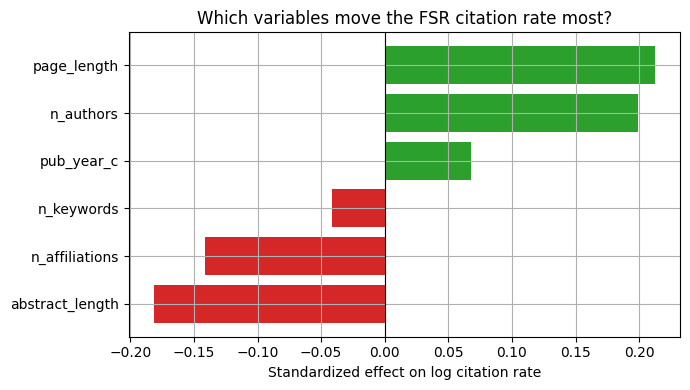

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
ordered = summary_table["standardized effect"].sort_values()
colors = ["#d62728" if v < 0 else "#2ca02c" for v in ordered]
ax.barh(ordered.index, ordered.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Standardized effect on log citation rate")
ax.set_title("Which variables move the FSR citation rate most?")
plt.tight_layout()
plt.show()


## 2.6 Is Negative Binomial the right family, and what does the surviving dispersion cost us?

Everything in §2.4 and §2.5 rests on one dispersion parameter. The model says

$$
\text{Var}(Y_i) \;=\; \mu_i + \alpha \mu_i^2, \qquad \hat\alpha = 1.7334
$$

and $\hat\alpha$ is estimated with a standard error of 0.099, so it is nowhere near zero. Two separate things follow from that, and they pull in opposite directions. The first is reassuring: Poisson would have been the wrong family, badly, and the NB is the right correction. The second is not: even after the correction, the spread left around each fitted mean is so large that the fitted mean is a weak description of any individual paper.

Take the arithmetic at FSR's own scale. At $\mu = 15$, roughly the sample mean, a Poisson would put the standard deviation at $\sqrt{15} \approx 3.9$ citations. The fitted NB puts it at $\sqrt{15 + 1.7334 \times 15^2} \approx 20$ citations, which is larger than the mean itself. That is not a small correction to a well-behaved model, it is a statement that the conditional distribution of citations is dominated by dispersion rather than by location.

In [20]:
from scipy import stats
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# --- Poisson on the same design, same offset, for a like-for-like comparison ---
res_pois = sm.Poisson(y, X, offset=offset).fit(disp=0)

alpha = res_offset.params["alpha"]
mu_bar = y.mean()

print("Family comparison (identical covariates and offset)")
print(f"  log-likelihood   Poisson {res_pois.llf:>10.1f}   NB {res_offset.llf:>10.1f}")
print(f"  AIC              Poisson {res_pois.aic:>10.1f}   NB {res_offset.aic:>10.1f}"
      f"   (NB better by {res_pois.aic - res_offset.aic:,.0f})")
print(f"  LR stat for alpha = 0: {2 * (res_offset.llf - res_pois.llf):,.0f} on 1 df")
pearson_disp = (((y - res_pois.predict(X, offset=offset)) ** 2) / res_pois.predict(X, offset=offset)).sum() / (len(y) - X.shape[1])
print(f"  Poisson Pearson dispersion: {pearson_disp:.1f}  (should be ~1 if Poisson held)")

print("\nLargest |z| under each family:")
print(f"  Poisson: page_length z = {res_pois.tvalues['page_length']:.1f}   NB: page_length z = {res_offset.tvalues['page_length']:.1f}")
print(f"  Under Poisson every covariate is 'significant' at p < 0.001, including n_keywords (z = {res_pois.tvalues['n_keywords']:.1f}),")
print(f"  which the NB puts at z = {res_offset.tvalues['n_keywords']:.2f}, p = {res_offset.pvalues['n_keywords']:.2f}.")

print(f"\nWhat alpha = {alpha:.4f} implies:  Var(Y) = mu + {alpha:.4f} * mu^2")
disp_rows = []
for m in [5.0, mu_bar, 50.0]:
    v = m + alpha * m ** 2
    disp_rows.append({"mu": m, "Poisson sd": np.sqrt(m), "NB sd": np.sqrt(v),
                      "sd inflation": np.sqrt(v / m)})
disp = pd.DataFrame(disp_rows).set_index("mu")
print(disp.round(2).to_string())
print(f"\nAt the sample mean mu = {mu_bar:.2f}, the NB conditional sd is {np.sqrt(mu_bar + alpha * mu_bar**2):.1f} citations,")
print(f"i.e. {np.sqrt(mu_bar + alpha*mu_bar**2)/mu_bar:.2f} times the mean itself. Observed marginal sd = {y.std(ddof=1):.2f}.")

Family comparison (identical covariates and offset)
  log-likelihood   Poisson   -10549.6   NB    -2008.9
  AIC              Poisson    21113.3   NB     4033.7   (NB better by 17,080)
  LR stat for alpha = 0: 17,082 on 1 df
  Poisson Pearson dispersion: 76.9  (should be ~1 if Poisson held)

Largest |z| under each family:
  Poisson: page_length z = 26.4   NB: page_length z = 3.1
  Under Poisson every covariate is 'significant' at p < 0.001, including n_keywords (z = -7.2),
  which the NB puts at z = -0.63, p = 0.53.

What alpha = 1.7334 implies:  Var(Y) = mu + 1.7334 * mu^2
         Poisson sd   NB sd  sd inflation
mu                                       
5.0000       2.2400  6.9500        3.1100
15.1409      3.8900 20.3100        5.2200
50.0000      7.0700 66.2100        9.3600

At the sample mean mu = 15.14, the NB conditional sd is 20.3 citations,
i.e. 1.34 times the mean itself. Observed marginal sd = 43.76.


The AIC gap is about 17,000 and the Poisson's Pearson dispersion statistic is 77 where it should be near 1, so the choice of family is not a close call. The practical damage Poisson would have done is visible in the $z$-statistics: it declares `n_keywords` significant at $z = -7.2$, a variable the NB correctly reads as noise at $z = -0.63$, $p = 0.53$. Under-dispersion assumptions manufacture precision that is not there.

But note what the NB buys and what it does not. It buys honest standard errors. It does not buy a tight conditional distribution, because $\alpha$ is a *constant*: the same 1.7334 applies to a paper the model expects to earn 2 citations and a paper it expects to earn 45.

### 2.6.1 Where the fitted distribution actually misses

A rootogram compares the count distribution the fitted model implies against the one in the data. For each count $k$ we compute $\hat n_k = \sum_i P(Y_i = k \mid \hat\mu_i, \hat\alpha)$ and compare it with the observed frequency, on a square-root scale so the small frequencies in the tail stay visible. Bars are hung from the fitted curve: a bar that drops below zero means there are more papers at that count than the model expects, one that floats above zero means fewer.

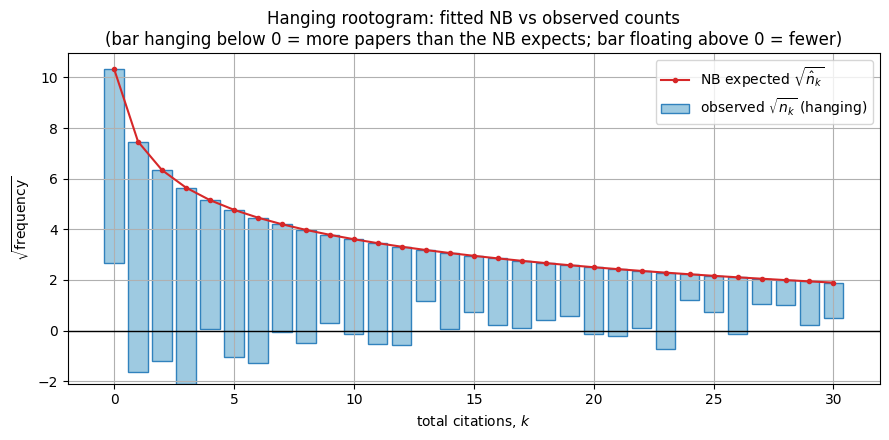

Counts in the body of the distribution:
    observed  NB expected      gap
0         59     106.8000 -47.8000
1         83      55.6000  27.4000
2         57      40.1000  16.9000
3         60      31.9000  28.1000
5         34      22.7000  11.3000
10        14      13.0000   1.0000
20         7       6.3000   0.7000
30         2       3.6000  -1.6000

Zeros: observed 59, NB expects 107. The model manufactures 48 papers with no citations that do not exist,
and is short 27 papers at k = 1 and 28 at k = 3.


In [21]:
# Fitted conditional means, and the NB size/prob parameterisation implied by alpha.
mu_hat = res_offset.predict(X, offset=offset).to_numpy()
size = 1.0 / alpha
prob = size / (size + mu_hat)

# Expected frequency of each count k, summed over papers: sum_i P(Y_i = k | mu_i, alpha).
ks = np.arange(0, 31)
exp_freq = np.array([stats.nbinom.pmf(k, size, prob).sum() for k in ks])
obs_freq = np.array([(y == k).sum() for k in ks])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(ks, np.sqrt(obs_freq), bottom=np.sqrt(exp_freq) - np.sqrt(obs_freq),
       width=0.8, color="#9ecae1", edgecolor="#3182bd", label=r"observed $\sqrt{n_k}$ (hanging)")
ax.plot(ks, np.sqrt(exp_freq), color="#d62728", marker="o", ms=3, lw=1.5,
        label=r"NB expected $\sqrt{\hat{n}_k}$")
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("total citations, $k$")
ax.set_ylabel(r"$\sqrt{\text{frequency}}$")
ax.set_title("Hanging rootogram: fitted NB vs observed counts\n(bar hanging below 0 = more papers than the NB expects; bar floating above 0 = fewer)")
ax.legend()
plt.tight_layout(); plt.show()

comp = pd.DataFrame({"observed": obs_freq, "NB expected": exp_freq}, index=ks).loc[[0,1,2,3,5,10,20,30]]
comp["gap"] = comp["observed"] - comp["NB expected"]
print("Counts in the body of the distribution:")
print(comp.round(1).to_string())
print(f"\nZeros: observed {obs_freq[0]}, NB expects {exp_freq[0]:.0f}. The model manufactures "
      f"{exp_freq[0] - obs_freq[0]:.0f} papers with no citations that do not exist,")
print(f"and is short {obs_freq[1] - exp_freq[1]:.0f} papers at k = 1 and {obs_freq[3] - exp_freq[3]:.0f} at k = 3.")

The misfit is systematic, not random scatter. The model expects 107 uncited papers and there are 59, so it invents 48 zeros that do not exist, and it pays for them by being short 27 papers at $k=1$ and 28 at $k=3$. The real distribution has a denser, more compact body than a Negative Binomial with this $\alpha$ can produce. That matters for the tail question, because the same single $\alpha$ that is stretching the body has to do the work in the tail as well.

### 2.6.2 What the fitted model thinks FSR's tail looks like

The direct test is to generate synthetic journals from the fitted model and ask whether they look like FSR. We draw 2,000 replicate datasets of 582 papers, each paper $i$ drawn from $\text{NegBin}(\hat\mu_i, \hat\alpha)$, and compare the simulated upper tail against the observed one.

In [22]:
rng = np.random.default_rng(42)
B = 2000
sim = rng.negative_binomial(size, prob, size=(B, len(mu_hat)))   # B synthetic FSR journals

tail_rows = []
for c in [26, 50, 100, 200]:
    cnt = (sim >= c).sum(axis=1)
    tail_rows.append({"threshold": f">= {c}", "observed": int((y >= c).sum()),
                      "NB expected": cnt.mean(),
                      "NB 95% interval": f"[{np.percentile(cnt, 2.5):.0f}, {np.percentile(cnt, 97.5):.0f}]"})
tail = pd.DataFrame(tail_rows).set_index("threshold")
print("Papers above each citation threshold: real FSR vs 2,000 simulated FSRs from the fitted NB")
print(tail.round(1).to_string())

sim_max = sim.max(axis=1)
sim_sd = sim.std(axis=1, ddof=1)
print(f"\nMost-cited paper:  observed {y.max()}, "
      f"NB simulated median {np.median(sim_max):.0f}, 95% interval [{np.percentile(sim_max, 2.5):.0f}, {np.percentile(sim_max, 97.5):.0f}]")
print(f"  P(a simulated FSR produces a paper with >= {y.max()} citations) = {(sim_max >= y.max()).mean():.4f}  "
      f"(0 of {B} replications)")
print(f"\nMarginal sd:       observed {y.std(ddof=1):.1f}, NB simulated median {np.median(sim_sd):.1f} "
      f"[{np.percentile(sim_sd, 2.5):.1f}, {np.percentile(sim_sd, 97.5):.1f}]")
print(f"90th percentile:   observed {np.percentile(y, 90):.0f}, NB simulated median {np.median(np.percentile(sim, 90, axis=1)):.0f}")

Papers above each citation threshold: real FSR vs 2,000 simulated FSRs from the fitted NB
           observed  NB expected NB 95% interval
threshold                                       
>= 26            63     104.7000       [88, 121]
>= 50            33      41.0000        [30, 53]
>= 100           18       8.2000         [3, 14]
>= 200            6       0.6000          [0, 3]

Most-cited paper:  observed 678, NB simulated median 196, 95% interval [129, 365]
  P(a simulated FSR produces a paper with >= 678 citations) = 0.0000  (0 of 2000 replications)

Marginal sd:       observed 43.8, NB simulated median 23.2 [19.4, 28.6]
90th percentile:   observed 26, NB simulated median 40


This is the result that decides the rest of Part 2, and it goes in both directions at once.

In the **moderate tail**, the NB over-predicts substantially. It expects 105 papers at 26 or more citations, with a 95% interval of [88, 121]. FSR has 63. The observed value is not merely below the expectation, it sits well outside the interval, so this is a genuine misfit rather than sampling noise. The model's own 90th percentile of the citation distribution is 40 citations where FSR's is 26.

In the **extreme tail**, the NB under-predicts just as clearly. It expects 8 papers at 100 or more citations, interval [3, 14], and FSR has 18. At 200 or more it expects 0.6 and FSR has 6. Most tellingly, across 2,000 simulated journals, not one produced a paper matching FSR's most-cited article at 678 citations. The simulated maximum has a median of 196 and a 97.5th percentile of 365. The single paper that most defines "high hitter" at FSR is an event the fitted model treats as essentially impossible.

So the fitted marginal standard deviation is 23 against an observed 43.8. The NB has not absorbed FSR's dispersion, it has redistributed it: too much probability spread over the 26-to-60 region, not nearly enough at 100-plus. One $\alpha$ cannot make the body compact and the tail heavy at the same time. The shape it is forced to choose is wrong in both places.

## 2.7 What a pseudo R² of 0.0061 says, and what it does not

McFadden's pseudo $R^2$ is

$$
R^2_{\text{McF}} \;=\; 1 - \frac{\log L_{\text{full}}}{\log L_{\text{null}}}
$$

a ratio of log-likelihoods, not a proportion of variance. It is not on the same scale as an OLS $R^2$ and should not be read as "0.6% of variation explained". McFadden himself noted that values in the 0.2-0.4 band already represent excellent fit for discrete models. There is no equivalent of "$R^2 = 0.9$ means nearly all the variation".

What it does mean is that adding six covariates moved the log-likelihood from $-2021.3$ to $-2008.9$, a gain of 12.4 log-likelihood units. That gain is real: the likelihood-ratio test gives $p = 0.00037$, so the covariates are jointly significant. Statistical significance and explanatory reach are different questions, and here they separate about as far as they can. The useful check is not the pseudo $R^2$ at all, it is how far the fitted values can actually travel.

In [23]:
# The covariate-driven part of the fitted value: exp(b0 + b'x), i.e. citations per year with age divided out.
rate_hat = np.exp(X.to_numpy() @ res_offset.params.drop("alpha").to_numpy())

print(f"McFadden pseudo R^2 = 1 - LL_full/LL_null = 1 - ({res_offset.llf:.1f})/({res_offset.llnull:.1f}) "
      f"= {1 - res_offset.llf / res_offset.llnull:.6f}")
print(f"LR statistic {res_offset.llr:.1f} on {int(res_offset.df_model)} df, p = {res_offset.llr_pvalue:.5f}  "
      "-> the covariates are jointly significant.\n")

print("Spread of what the model predicts vs spread of what actually happened:")
print(f"  fitted mu_i:        min {mu_hat.min():.2f}   max {mu_hat.max():.2f}   range {mu_hat.max() - mu_hat.min():.1f}")
print(f"  observed citations: min {y.min():.0f}      max {y.max():.0f}    range {y.max() - y.min():.0f}")
print(f"  fitted range / observed range = {(mu_hat.max() - mu_hat.min()) / (y.max() - y.min()):.3f}")
print(f"  sd(fitted) / sd(observed)     = {mu_hat.std(ddof=1) / y.std(ddof=1):.3f}   "
      f"(var ratio {mu_hat.var(ddof=1) / y.var(ddof=1):.3f})")

print(f"\n  Pearson corr(fitted, observed)  = {np.corrcoef(mu_hat, y)[0, 1]:.3f}")
print(f"  Spearman corr(fitted, observed) = {pd.Series(mu_hat).corr(pd.Series(y), method='spearman'):.3f}")

print("\nHow far can the covariates alone move the citation RATE (age divided out)?")
print(f"  full range of exp(b0 + b'x): {rate_hat.min():.2f} to {rate_hat.max():.2f} cites/yr "
      f"= a factor of {rate_hat.max() / rate_hat.min():.1f} across the whole covariate space")
print(f"  5th to 95th percentile:      {np.percentile(rate_hat, 5):.2f} to {np.percentile(rate_hat, 95):.2f} "
      f"= a factor of {np.percentile(rate_hat, 95) / np.percentile(rate_hat, 5):.2f}")
print(f"  interquartile:               factor of {np.percentile(rate_hat, 75) / np.percentile(rate_hat, 25):.2f}")
print(f"\n  Observed citations span 0 to {y.max():.0f}, a range the covariates cannot begin to generate.")

McFadden pseudo R^2 = 1 - LL_full/LL_null = 1 - (-2008.9)/(-2021.3) = 0.006137
LR statistic 24.8 on 6 df, p = 0.00037  -> the covariates are jointly significant.

Spread of what the model predicts vs spread of what actually happened:
  fitted mu_i:        min 0.56   max 48.37   range 47.8
  observed citations: min 0      max 678    range 678
  fitted range / observed range = 0.071
  sd(fitted) / sd(observed)     = 0.177   (var ratio 0.031)

  Pearson corr(fitted, observed)  = 0.220
  Spearman corr(fitted, observed) = 0.347

How far can the covariates alone move the citation RATE (age divided out)?
  full range of exp(b0 + b'x): 0.34 to 2.74 cites/yr = a factor of 8.0 across the whole covariate space
  5th to 95th percentile:      0.58 to 1.54 = a factor of 2.65
  interquartile:               factor of 1.44

  Observed citations span 0 to 678, a range the covariates cannot begin to generate.


Three numbers carry this. First, the fitted means span 0.56 to 48.4 citations while the data spans 0 to 678: the model's entire predictive range covers 7% of the observed range. Second, once age is divided out, the covariates move the predicted citation *rate* by a factor of 2.65 between the 5th and 95th percentile of the covariate space, and only 1.44 across the interquartile range. Even at the absolute extremes of every covariate simultaneously the rate moves by a factor of 8, from 0.34 to 2.74 citations per year. Third, the fitted values correlate with the outcome at $r = 0.22$, so $\text{var}(\hat\mu)$ is 3% of $\text{var}(y)$.

The honest summary of §2.4 is therefore: `n_authors`, `page_length` and `abstract_length` genuinely shift the expected citation rate, the evidence for that is sound, and the shift they produce is roughly a doubling across nearly the whole realistic range of paper characteristics. Meanwhile actual citation counts vary by three orders of magnitude. The covariates are real and small. Nothing about a richer mean model would change that, because the problem is not the estimator.

## 2.8 Why a mean-based model structurally cannot answer a tail question

This is the substantive objection, and it is not about fit quality. Suppose the NB fitted perfectly. It would still be the wrong tool for the question AFS is asking.

The NB estimates $\mathbb{E}[Y_i \mid \mathbf{x}_i] = \mu_i$, and pairs that single conditional mean with a dispersion parameter $\alpha$ that does not depend on $\mathbf{x}_i$. The consequence is a strong structural restriction: the *shape* of the conditional distribution is identical for every paper. Covariates can slide the distribution left or right along the count axis, but they cannot make it more skewed for one paper than another, cannot widen its spread independently of its centre, and cannot move its 90th percentile except by moving its mean. Every conditional quantile is a deterministic function of $\mu_i$ alone.

"Which papers become high hitters" is a question about the upper conditional quantile, $Q_{0.9}(Y \mid \mathbf{x})$. Under the NB, the only way that quantile can move is in lockstep with the mean, at a fixed ratio set by $\alpha$. If the real tail does not behave that way, the NB cannot represent it no matter how well it is estimated. That is testable, so let us test it.

,n,fitted_mu,obs_mean,obs_median,obs_q90,obs_max,obs q90/mean,NB-implied q90/mean
mu_decile,,,,,,,,
1,59,2.2500,2.5800,1.0000,6.0000,18,2.3300,2.6600
2,58,6.2000,3.1700,2.0000,8.3000,20,2.6200,2.7400
3,58,9.2900,11.4700,5.0000,23.2000,149,2.0200,2.6900
4,58,11.6200,15.3300,5.5000,23.3000,174,1.5200,2.6700
5,58,13.6200,10.9700,5.5000,16.6000,193,1.5100,2.6400
6,58,15.8200,7.8600,4.0000,15.6000,100,1.9800,2.6500
7,58,17.6200,17.4300,8.0000,36.1000,171,2.0700,2.6700
8,58,19.5600,20.6200,6.0000,34.2000,346,1.6600,2.6600
9,58,22.0100,29.3300,8.0000,62.2000,334,2.1200,2.6400



Observed  q90/mean across deciles: 1.51 to 2.62  (varies by a factor of 1.73)
NB-implied q90/mean across deciles: 2.64 to 2.74  (varies by a factor of 1.04)

The NB is locked into a near-constant tail-to-mean ratio because a single alpha fixes the shape
for every paper. The data will not hold still at that ratio.

Deciles 3-5 have fitted means of 9.3-13.6 citations, yet contain papers with
149, 174 and 193 citations. For a paper with mu = 11.6, the fitted NB puts its own 90th
percentile at 31 citations and its 99.9th at 117.

Across deciles 3-10 the fitted mean rises 3.1x (9.3 -> 29.1). Over the same span the observed
  median  moves 4.0 -> 8.0 (a 2.0x band, and non-monotone),
  mean    moves 7.9 -> 32.6,
  90th pct moves 15.6 -> 62.2.
Almost all of the ordering the fitted mean achieves is ordering of the tail, not of the typical paper.


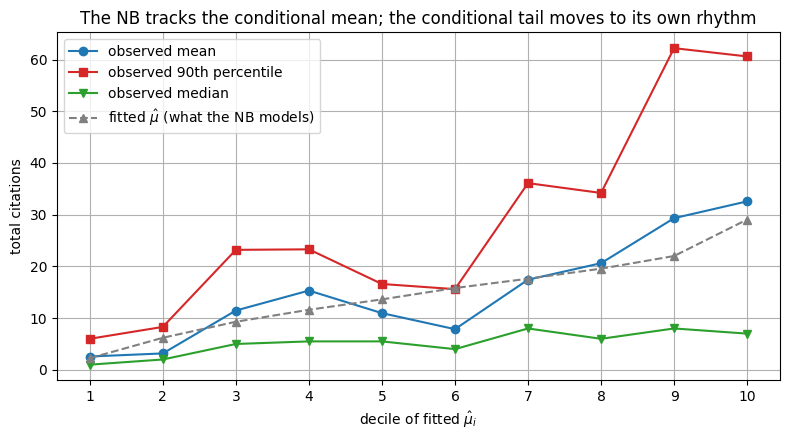

In [24]:
fsr["nb_fitted"] = mu_hat
fsr["mu_decile"] = pd.qcut(fsr["nb_fitted"], 10, labels=False) + 1

bins = fsr.groupby("mu_decile").agg(
    n=("cited_by", "size"),
    fitted_mu=("nb_fitted", "mean"),
    obs_mean=("cited_by", "mean"),
    obs_median=("cited_by", "median"),
    obs_q90=("cited_by", lambda s: s.quantile(0.90)),
    obs_max=("cited_by", "max"),
)
bins["obs q90/mean"] = bins["obs_q90"] / bins["obs_mean"]
# What the fitted NB says that ratio MUST be, given each bin's mean and the single shared alpha.
bins["NB-implied q90/mean"] = [stats.nbinom.ppf(0.90, size, size / (size + m)) / m for m in bins["fitted_mu"]]
display(bins.round(2))

lo, hi = bins["obs q90/mean"].min(), bins["obs q90/mean"].max()
nlo, nhi = bins["NB-implied q90/mean"].min(), bins["NB-implied q90/mean"].max()
print(f"\nObserved  q90/mean across deciles: {lo:.2f} to {hi:.2f}  (varies by a factor of {hi/lo:.2f})")
print(f"NB-implied q90/mean across deciles: {nlo:.2f} to {nhi:.2f}  (varies by a factor of {nhi/nlo:.2f})")
print("\nThe NB is locked into a near-constant tail-to-mean ratio because a single alpha fixes the shape")
print("for every paper. The data will not hold still at that ratio.")
print(f"\nDeciles 3-5 have fitted means of {bins.loc[3,'fitted_mu']:.1f}-{bins.loc[5,'fitted_mu']:.1f} citations, yet contain papers with")
print(f"{bins.loc[3,'obs_max']:.0f}, {bins.loc[4,'obs_max']:.0f} and {bins.loc[5,'obs_max']:.0f} citations. For a paper with mu = {bins.loc[4,'fitted_mu']:.1f}, the fitted NB puts its own 90th")
print(f"percentile at {stats.nbinom.ppf(0.90, size, size/(size+bins.loc[4,'fitted_mu'])):.0f} citations and its 99.9th at "
      f"{stats.nbinom.ppf(0.999, size, size/(size+bins.loc[4,'fitted_mu'])):.0f}.")

top = bins.loc[3:, ["obs_mean", "obs_median", "obs_q90"]]
print(f"\nAcross deciles 3-10 the fitted mean rises {bins.loc[10,'fitted_mu']/bins.loc[3,'fitted_mu']:.1f}x "
      f"({bins.loc[3,'fitted_mu']:.1f} -> {bins.loc[10,'fitted_mu']:.1f}). Over the same span the observed")
print(f"  median  moves {top['obs_median'].min():.1f} -> {top['obs_median'].max():.1f} (a {top['obs_median'].max()/top['obs_median'].min():.1f}x band, and non-monotone),")
print(f"  mean    moves {top['obs_mean'].min():.1f} -> {top['obs_mean'].max():.1f},")
print(f"  90th pct moves {top['obs_q90'].min():.1f} -> {top['obs_q90'].max():.1f}.")
print("Almost all of the ordering the fitted mean achieves is ordering of the tail, not of the typical paper.")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(bins.index, bins["obs_mean"], "o-", color="#1f77b4", label="observed mean")
ax.plot(bins.index, bins["obs_q90"], "s-", color="#d62728", label="observed 90th percentile")
ax.plot(bins.index, bins["obs_median"], "v-", color="#2ca02c", label="observed median")
ax.plot(bins.index, bins["fitted_mu"], "^--", color="gray", label=r"fitted $\hat\mu$ (what the NB models)")
ax.set_xlabel(r"decile of fitted $\hat\mu_i$")
ax.set_ylabel("total citations")
ax.set_title("The NB tracks the conditional mean; the conditional tail moves to its own rhythm")
ax.set_xticks(bins.index)
ax.legend()
plt.tight_layout(); plt.show()

The last two columns are the test. The NB, holding $\alpha$ fixed at 1.7334, insists that the ratio of a paper's 90th percentile to its mean sits between 2.64 and 2.74 regardless of which decile it belongs to: a band of 4%. The data puts that ratio anywhere from 1.51 to 2.62, a factor of 1.73, and the variation has no relationship to the fitted mean. The restriction the NB imposes is not one the data satisfies.

The observed median column is more damaging still. Across deciles 3 to 10 the fitted mean rises 3.1-fold, from 9.3 to 29.1. Over that same span the observed median wanders between 4 and 8 and is not even monotone, while the observed 90th percentile climbs from 15.6 to 62.2. Almost everything the fitted mean is ordering is tail behaviour. For a typical FSR paper the model has close to nothing to say: whichever decile of $\hat\mu$ it lands in, the median outcome is about five citations.

And the mean carries no information about how extreme the extremes can be. Deciles 3, 4 and 5 have fitted means of 9.3, 11.6 and 13.6 citations, and contain papers cited 149, 174 and 193 times. For a paper with $\mu = 11.6$, the fitted NB places its 90th percentile at 31 citations and its 99.9th at 117. A 174-citation outcome from that paper is, under the model, an event of roughly one in several thousand. There are three of them in three adjacent deciles.

### 2.8.1 The high-hitter label, and what the mean model recovers

Define a high hitter as a paper in the top 10% by total citations. This is a fixed cutoff on the raw count, so unlike the NB's rate-based coefficients it does not adjust for age, a problem taken up in §2.9. Then take the §2.4 model's fitted $\hat\mu_i$, threshold it at its own 90th percentile to match the 10% base rate, and see which papers it picks.

In [25]:
threshold_actual = fsr["cited_by"].quantile(0.90)
fsr["high_hitter"] = (fsr["cited_by"] >= threshold_actual).astype(int)
n_high, base_rate = fsr["high_hitter"].sum(), fsr["high_hitter"].mean()
print(f"High-hitter cutoff: >= {threshold_actual:.0f} citations ({n_high} of {len(fsr)} papers, {base_rate:.1%})")

nb_threshold = fsr["nb_fitted"].quantile(0.90)
fsr["nb_pred_high"] = (fsr["nb_fitted"] >= nb_threshold).astype(int)

cm_nb = confusion_matrix(fsr["high_hitter"], fsr["nb_pred_high"])
tn, fp, fn, tp = cm_nb.ravel()
print("\nConfusion matrix (rows = actual, cols = predicted):")
print(pd.DataFrame(cm_nb, index=["actual: not high hitter", "actual: high hitter"],
                   columns=["pred: not high hitter", "pred: high hitter"]))
print(f"\nTP={tp}  FP={fp}  TN={tn}  FN={fn}")
print(classification_report(fsr["high_hitter"], fsr["nb_pred_high"], digits=2))

auc_nb = roc_auc_score(fsr["high_hitter"], fsr["nb_fitted"])
print(f"AUC (threshold-free): {auc_nb:.3f}")

# What would flagging papers at random achieve? The benchmark accuracy = 0.84 hides.
n_flagged = tp + fp
expected_tp = n_flagged * base_rate
print(f"\nBenchmark: the rule flags {n_flagged} papers and catches {tp} true high hitters.")
print(f"  Flagging {n_flagged} papers at random would catch {expected_tp:.1f} on average.")
print(f"  Lift over random = {tp / expected_tp:.2f}x.")
print(f"  P(catching >= {tp} by chance alone) = {stats.hypergeom.sf(tp - 1, len(fsr), n_high, n_flagged):.4f} (hypergeometric).")
print(f"  Accuracy of {(tp + tn) / len(fsr):.2f} is not informative here: always predicting 'not a high hitter'")
print(f"  scores {1 - base_rate:.2f} while catching none of the {n_high}.")

High-hitter cutoff: >= 26 citations (63 of 582 papers, 10.8%)

Confusion matrix (rows = actual, cols = predicted):
                         pred: not high hitter  pred: high hitter
actual: not high hitter                    473                 46
actual: high hitter                         50                 13

TP=13  FP=46  TN=473  FN=50
              precision    recall  f1-score   support

           0       0.90      0.91      0.91       519
           1       0.22      0.21      0.21        63

    accuracy                           0.84       582
   macro avg       0.56      0.56      0.56       582
weighted avg       0.83      0.84      0.83       582

AUC (threshold-free): 0.712

Benchmark: the rule flags 59 papers and catches 13 true high hitters.
  Flagging 59 papers at random would catch 6.4 on average.
  Lift over random = 2.04x.
  P(catching >= 13 by chance alone) = 0.0062 (hypergeometric).
  Accuracy of 0.84 is not informative here: always predicting 'not a high hitter'


Read the confusion matrix against the right benchmark. The rule flags 59 papers and catches 13 of the 63 real high hitters. Flagging 59 papers at random would catch 6.4. So the NB does carry signal: a lift of 2.04 times chance, with a hypergeometric $p$ of 0.0062, which is not a fluke. It is also not usable. An editor working this list reads 59 papers to find 13, having missed 50, and would have found 6 of those 13 by drawing names from a hat.

The accuracy figure of 0.84 should be ignored entirely. A rule that flags nothing scores 0.89 and finds no high hitters at all. The threshold-free AUC of 0.712 is the honest summary, and §2.9 shows where most of it comes from.

## 2.9 The raw high-hitter label is partly just a label for "old"

There is a mismatch built into §2.8.1 that has to be confronted before any of it can be interpreted. The NB model is rate-based: age sits in the offset, and coefficients describe citations per year. The high-hitter label is count-based and not age-adjusted at all. A 30-year-old paper needs 0.87 citations a year to clear 26; a 5-year-old paper needs 5.2. The label is therefore easier to earn the longer a paper has existed.

In [26]:
hh, oth = fsr.loc[fsr["high_hitter"] == 1, "age"], fsr.loc[fsr["high_hitter"] == 0, "age"]
print(f"Age of the {len(hh)} high hitters:  mean {hh.mean():.1f}, median {hh.median():.0f} years")
print(f"Age of the other {len(oth)} papers:  mean {oth.mean():.1f}, median {oth.median():.0f} years")
print(f"Mann-Whitney U test of equal age distributions: p = {stats.mannwhitneyu(hh, oth).pvalue:.2e}")

fsr["age_tertile"] = pd.qcut(fsr["age"], 3, labels=["youngest", "middle", "oldest"])
tert = fsr.groupby("age_tertile", observed=True).agg(
    n=("age", "size"), age_range=("age", lambda s: f"{s.min():.0f}-{s.max():.0f} yrs"),
    high_hitters=("high_hitter", "sum"), pct_high=("high_hitter", lambda s: 100 * s.mean()))
print("\nWhere the high hitters live:")
print(tert.round(1).to_string())
print(f"\nA paper in the oldest tertile is {tert.loc['oldest','pct_high'] / tert.loc['youngest','pct_high']:.1f}x "
      "as likely to be labelled a high hitter as one in the youngest.")

# --- Direct logistic model on the raw label, log_age as a control ---
X_logit = sm.add_constant(fsr[["log_age"] + feat_cols])
logit_direct = sm.Logit(fsr["high_hitter"], X_logit).fit(disp=0)
print(logit_direct.summary())

fsr["logit_pred"] = logit_direct.predict(X_logit)
auc_direct = roc_auc_score(fsr["high_hitter"], fsr["logit_pred"])
print(f"\nAUC, direct logistic model: {auc_direct:.3f}    AUC, NB fitted mean: {auc_nb:.3f}")

b_age = logit_direct.params["log_age"]
print(f"\nlog_age coefficient = {b_age:.3f}. Because age enters as a log, this is an elasticity on the odds:")
print(f"  doubling a paper's age multiplies its odds of being a high hitter by 2^{b_age:.2f} = {2 ** b_age:.0f}")
print(f"  a 25-year-old paper vs a 5-year-old one: odds ratio (25/5)^{b_age:.2f} = {5 ** b_age:,.0f}")
print(f"  by comparison, one extra author multiplies the odds by only {np.exp(logit_direct.params['n_authors']):.2f}")

Age of the 63 high hitters:  mean 21.2, median 22 years
Age of the other 519 papers:  mean 16.3, median 16 years
Mann-Whitney U test of equal age distributions: p = 2.55e-05

Where the high hitters live:
               n  age_range  high_hitters  pct_high
age_tertile                                        
youngest     203   1-12 yrs             8    3.9000
middle       193  13-22 yrs            27   14.0000
oldest       186  23-34 yrs            28   15.1000

A paper in the oldest tertile is 3.8x as likely to be labelled a high hitter as one in the youngest.
                           Logit Regression Results                           
Dep. Variable:            high_hitter   No. Observations:                  582
Model:                          Logit   Df Residuals:                      574
Method:                           MLE   Df Model:                            7
Date:                Tue, 15 Sep 2026   Pseudo R-squ.:                  0.1037
Time:                        07:49:15  

High hitters average 21.2 years old against 16.3 for everyone else, $p = 2.6 \times 10^{-5}$. Only 8 of the 203 papers in the youngest tertile carry the label, 3.9%, against 15.1% in the oldest.

The logistic model makes it explicit. The `log_age` coefficient of 5.17 is an elasticity on the odds: doubling a paper's age multiplies its odds of being labelled a high hitter by $2^{5.17} = 36$. A 25-year-old paper has roughly 4,100 times the odds of a 5-year-old one. Against that, an extra author, the strongest content effect in the model, multiplies the odds by 1.54. The single strongest predictor of the raw high-hitter label is being old, and it is not close.

This has a direct consequence for the guiding question. Question D asks whether breakout papers can be **spotted early**. A label whose dominant driver is age is close to unanswerable in those terms, because the variable doing the predicting is the one thing a new paper cannot have.

### 2.9.1 An age-adjusted alternative label

The natural fix is to define the top decile on citations per year rather than on the raw count. If the two definitions largely agreed, the age problem would be cosmetic.

In [27]:
fsr["cites_per_year"] = fsr["cited_by"] / fsr["age"]
rate_cut = fsr["cites_per_year"].quantile(0.90)
fsr["high_rate"] = (fsr["cites_per_year"] >= rate_cut).astype(int)
print(f"Age-adjusted label: top 10% by citations per year, cutoff >= {rate_cut:.2f} cites/yr "
      f"({fsr['high_rate'].sum()} papers, {fsr['high_rate'].mean():.1%})")

both = ((fsr["high_hitter"] == 1) & (fsr["high_rate"] == 1)).sum()
raw_only = ((fsr["high_hitter"] == 1) & (fsr["high_rate"] == 0)).sum()
rate_only = ((fsr["high_hitter"] == 0) & (fsr["high_rate"] == 1)).sum()
print(f"\nOverlap: {both} papers carry both labels.")
print(f"  {raw_only} of the {fsr['high_hitter'].sum()} raw high hitters are NOT in the top 10% by rate.")
print(f"  {rate_only} papers in the top 10% by rate are NOT raw high hitters.")
print(f"  Jaccard agreement = {both / ((fsr['high_hitter'] | fsr['high_rate']).sum()):.3f}")

cols = ["title", "year", "age", "cited_by", "cites_per_year"]
print("\nRaw high hitters the rate label rejects (old, slow accumulation):")
print(fsr[(fsr["high_hitter"] == 1) & (fsr["high_rate"] == 0)].nlargest(3, "cited_by")[cols].to_string(index=False))
print("\nTop-10%-by-rate papers the raw label misses (young, fast accumulation):")
print(fsr[(fsr["high_hitter"] == 0) & (fsr["high_rate"] == 1)].nlargest(3, "cites_per_year")[cols].to_string(index=False))

print("\nHigh hitters by age tertile under each label definition:")
print(fsr.groupby("age_tertile", observed=True).agg(
    n=("age", "size"),
    pct_raw_label=("high_hitter", lambda s: 100 * s.mean()),
    pct_rate_label=("high_rate", lambda s: 100 * s.mean())).round(1).to_string())

Age-adjusted label: top 10% by citations per year, cutoff >= 2.00 cites/yr (61 papers, 10.5%)

Overlap: 39 papers carry both labels.
  24 of the 63 raw high hitters are NOT in the top 10% by rate.
  22 papers in the top 10% by rate are NOT raw high hitters.
  Jaccard agreement = 0.459

Raw high hitters the rate label rejects (old, slow accumulation):
                                                                                  title  year  age  cited_by  cites_per_year
Household insolvency: A review of household debt repayment, delinquency, and bankruptcy  1995   30        58          1.9333
                  Financial Inhibition, Financial Activation, and Saving for Retirement  2003   22        42          1.9091
                                        Asset allocation, life expectancy and shortfall  1994   31        42          1.3548

Top-10%-by-rate papers the raw label misses (young, fast accumulation):
                                                                  title  y

They do not agree. Only 39 papers carry both labels, a Jaccard agreement of 0.46. Twenty-four of the 63 raw high hitters fall out, and 22 different papers come in.

The papers name the problem precisely. "Household insolvency: A review of household debt repayment, delinquency, and bankruptcy" (1995) has 58 citations and clears the raw cutoff comfortably, but that is 1.93 citations a year over thirty years. "Investment literacy, overconfidence and cryptocurrency investment" (2023) has 18 citations in two years, a rate of 9.0 per year, nearly five times the pace, and the raw label does not see it. If AFS wants to know what is working now, the second paper is the far more informative observation, and the analysis in §2.8.1 discards it.

The tertile comparison confirms the reversal is complete. Under the raw label the oldest tertile holds 15.1% of high hitters against the youngest tertile's 3.9%. Under the rate label it flips: 8.1% oldest, 14.8% youngest. The two definitions do not just disagree at the margin, they point in opposite directions with respect to age.

### 2.9.2 So how much of that AUC was ever about the paper?

The logistic model's AUC of 0.723 against the NB's 0.712 might look like a classifier fixes something. It does not, and the way to show that is to strip age out and see what survives. One trap first: `pub_year_c` is defined as `year - mean(year)` while `age` is `2025 - year`, so the two are perfectly negatively collinear. Dropping `log_age` while keeping `pub_year_c` does not remove age from the model, it just changes the functional form. A genuinely age-free model has to drop both.

In [28]:
# CAUTION: pub_year_c = year - mean(year) and age = 2025 - year, so pub_year_c is an exact
# negative linear transform of age. Simply dropping log_age does NOT remove age from the model.
print(f"corr(age, pub_year_c) = {np.corrcoef(fsr['age'], fsr['pub_year_c'])[0,1]:.4f}  "
      "<- perfectly collinear; pub_year_c IS age, rescaled.")

content_cols = ["n_authors", "n_affiliations", "n_keywords", "page_length", "abstract_length"]

def fit_auc(cols, label):
    Xc = sm.add_constant(fsr[cols])
    m = sm.Logit(fsr[label], Xc).fit(disp=0)
    return roc_auc_score(fsr[label], m.predict(Xc)), m

ladder = []
for cols, name in [(["log_age"] + feat_cols, "all covariates + log_age"),
                   (feat_cols,               "drop log_age, keep pub_year_c"),
                   (["log_age"],             "age alone"),
                   (content_cols,            "content only (no age, no year)")]:
    a, _ = fit_auc(cols, "high_hitter")
    ladder.append({"predictors": name, "AUC on raw label": a})
ladder = pd.DataFrame(ladder).set_index("predictors")
ladder["AUC on rate label"] = [fit_auc(c, "high_rate")[0] for c, _ in
    [(["log_age"] + feat_cols, 0), (feat_cols, 0), (["log_age"], 0), (content_cols, 0)]]
display(ladder.round(3))

print(f"\nAge alone reaches AUC {ladder.loc['age alone','AUC on raw label']:.3f} on the raw label.")
print(f"All five content covariates together, with age and calendar year fully removed, reach "
      f"{ladder.loc['content only (no age, no year)','AUC on raw label']:.3f}:")
print("less than age by itself. Adding age back buys only "
      f"{ladder.loc['all covariates + log_age','AUC on raw label'] - ladder.loc['content only (no age, no year)','AUC on raw label']:.3f} AUC.")

_, m_rate = fit_auc(["log_age"] + feat_cols, "high_rate")
print(f"\nOn the age-adjusted label the log_age coefficient flips sign: "
      f"{m_rate.params['log_age']:.3f} (p = {m_rate.pvalues['log_age']:.3f}),")
print("i.e. once the target is a rate, OLDER papers are LESS likely to be in the top decile,")
print("which is what Part 1's peak-and-decline trajectory predicts.")
print(f"n_authors survives as the only near-significant content term: coef "
      f"{m_rate.params['n_authors']:.3f}, p = {m_rate.pvalues['n_authors']:.3f}.")

corr(age, pub_year_c) = -1.0000  <- perfectly collinear; pub_year_c IS age, rescaled.


,AUC on raw label,AUC on rate label
predictors,,
all covariates + log_age,0.7230,0.6520
"drop log_age, keep pub_year_c",0.6990,0.6340
age alone,0.6620,0.5930
"content only (no age, no year)",0.6520,0.6220



Age alone reaches AUC 0.662 on the raw label.
All five content covariates together, with age and calendar year fully removed, reach 0.652:
less than age by itself. Adding age back buys only 0.070 AUC.

On the age-adjusted label the log_age coefficient flips sign: -0.818 (p = 0.031),
i.e. once the target is a rate, OLDER papers are LESS likely to be in the top decile,
which is what Part 1's peak-and-decline trajectory predicts.
n_authors survives as the only near-significant content term: coef 0.318, p = 0.062.


The numbers are worse than the headline AUCs suggest, and they should be reported that way.

Age by itself scores 0.662 on the raw label. All five content covariates together, with age and calendar year fully removed, score 0.652: *less than age alone*. The full model's 0.723 is therefore 0.662 of age plus about 0.06 of everything else. Dropping `log_age` but keeping `pub_year_c` only falls to 0.699, which looks like a small loss and is in fact no loss at all, because age is still in the model under another name. That comparison would have been misleading, which is why it is in the table.

On the age-adjusted label the whole model falls to 0.652 and `log_age` flips sign to $-0.818$, $p = 0.031$: once the target is a rate rather than a count, older papers are *less* likely to be in the top decile. That is exactly what Part 1's peak-and-decline trajectory predicts, and it is reassuring that it shows up here independently. Only `n_authors` survives as a content-level predictor of high citation rate, at $p = 0.062$.

The conclusion is uncomfortable but clean: neither the NB's 0.712 nor the logistic model's 0.723 is evidence that paper-level characteristics identify breakout papers. Most of both numbers is age. The content-level factors AFS could actually act on carry roughly 0.65 AUC on either label, which is weak, and the classifier framing did nothing to change that because the problem was never the link function.

## 2.10 What quantile regression is being asked to fix

Pulling the four threads together, the Negative Binomial rate model fails this question in a specific way, and it is worth being precise about which failures quantile regression addresses and which it does not.

**What the NB got right and should be kept.** The offset is defensible: fitting `log(age)` freely returns 1.039 with a 95% CI of [0.647, 1.430]. The family choice is correct by a margin of 17,000 AIC points. The three significant covariates are genuinely significant, with honest standard errors, and §2.5's ranking of them stands. None of what follows overturns §2.4.

**What it cannot do, and why.**

1. One fixed $\alpha$ forces every paper to share a conditional distribution shape. Tested directly, that restriction fails: the NB requires the tail-to-mean ratio to sit in a 2.64-2.74 band and the data puts it between 1.51 and 2.62. Simulation shows the same failure from the other side, with the fitted model over-producing 26-plus papers by 105 to 63 while under-producing 100-plus papers by 8 to 18, and never once generating FSR's 678-citation article in 2,000 replications.

2. The conditional mean is a poor summary of a distribution this skewed. Across deciles 3 to 10 of $\hat\mu$, the observed median stays flat at four to eight citations while the observed 90th percentile quadruples. A model of the mean is answering a question about the average of a distribution whose average is not where any of the interesting behaviour lives.

3. Thresholding a mean model to classify tail membership recovers 13 of 63 high hitters against 6.4 by chance. That is real signal and unusable precision, and it is what happens when a tail question is answered with a location model.

**What quantile regression changes.** Estimating $Q_\tau(\log(1+Y) \mid \mathbf{x})$ separately at each $\tau$ removes the restriction that causes all three problems. The coefficient vector is allowed to differ by quantile, so a variable may move the median and the 90th percentile by different amounts, or in different directions, and the data decides rather than $\alpha$. Fitting at $\tau = 0.5$ and $\tau = 0.9$ and comparing the coefficients tests something §2.4 cannot express: whether the factors that lift a typical FSR paper are the same factors that produce a breakout. §2.5's standardized effects are averages over both regimes, so if the two regimes differ, §2.5 has been reporting a blend of them and attributing it to the mean.

Quantile regression also inherits two useful properties here. It is estimated by minimising a weighted absolute-deviation loss, so a single 678-citation paper does not exert the leverage on the fit that it does on any squared-error or likelihood-based mean model. And it makes no assumption about the shape of the conditional distribution at all, which is the assumption that just failed the decile test.

**What it does not fix, and must be stated in the write-up.** Quantile regression on the same six covariates will not manufacture explanatory power that is not in them. The content-level factors carry about 0.65 AUC on either label; nothing in a change of estimand changes that ceiling. And the age problem does not disappear: `log_age` has to stay in the specification as a control, and any coefficient read as "spotting papers early" must be read net of it. The claim quantile regression can support is narrow and worth having, which is whether the drivers of the tail differ from the drivers of the middle. It is not a better predictor of which paper will break out.

## 2.11 Quantile regression: modelling the tail rather than the average

§2.10 set out the restriction that has to go: the Negative Binomial's single dispersion parameter $\alpha = 1.7334$ is the same number for every paper, so the covariates may move the centre of a paper's citation distribution but cannot change how wide or how skewed it is. Quantile regression removes that restriction. Rather than one model for the mean, fit a separate model at each quantile of the conditional distribution and let the coefficients differ.

### The estimator

For a quantile level $\tau \in (0,1)$, model the conditional quantile as linear in the covariates:

$$
Q_\tau(y_i \mid \mathbf{x}_i) \;=\; \mathbf{x}_i^\top \boldsymbol\beta(\tau)
$$

and estimate $\boldsymbol\beta(\tau)$ by minimising the **check loss** (asymmetric absolute loss):

$$
\hat{\boldsymbol\beta}(\tau) \;=\; \arg\min_{\mathbf{b}} \; \sum_{i=1}^{N} \rho_\tau\!\left(y_i - \mathbf{x}_i^\top \mathbf{b}\right),
\qquad
\rho_\tau(u) \;=\; u\bigl(\tau - \mathbb{1}\{u < 0\}\bigr)
$$

$\rho_\tau$ charges $\tau |u|$ for under-predicting and $(1-\tau)|u|$ for over-predicting. At $\tau = 0.5$ the two weights are equal, the criterion reduces to the sum of absolute deviations, and the fit is the conditional median. At $\tau = 0.9$ under-prediction costs nine times as much as over-prediction, so the fitted surface is pushed up until only about 10% of the sample lies above it. Each $\tau$ therefore gets its own $\boldsymbol\beta(\tau)$, and the covariates are free to change the **spread and shape** of the conditional distribution, not only its location.

Two properties matter for what follows:

- **No distributional assumption.** The check loss is a loss function, not a likelihood. There is no Negative Binomial, no Poisson, no $\alpha$, and no assumption that the errors are identically distributed across papers. Heteroskedasticity is not a nuisance to be corrected here, it is the object of interest: a covariate whose $\beta(\tau)$ rises with $\tau$ is precisely a covariate that widens the conditional distribution.
- **Resistance to outliers in $y$.** The check loss is linear in the residual, not quadratic, so the single 678-citation paper contributes a bounded gradient rather than an enormous squared one. §2.19 tests this directly.

### Why $\log(1 + y)$ is the right response here

Quantiles are **equivariant to monotone transformations**. For any non-decreasing $h$,

$$
Q_\tau\bigl(h(Y) \mid \mathbf{x}\bigr) \;=\; h\bigl(Q_\tau(Y \mid \mathbf{x})\bigr)
$$

so the $\tau$-quantile of $\log(1+Y)$ *is* $\log(1 + {}$the $\tau$-quantile of $Y)$, and back-transforming a fitted value with $\exp(\cdot) - 1$ recovers the quantile of the raw citation count exactly. Nothing is lost and nothing needs a smearing correction. This is a property means do not have: $\mathbb{E}[\log Y] \neq \log \mathbb{E}[Y]$ by Jensen's inequality, which is why a mean model fitted on a log scale cannot be read back on the count scale without a bias adjustment.

We take the transformation because it fixes the units of the coefficients. On the raw count scale the check loss is in citations, so a coefficient would say "this many extra citations", the fit would be dominated by the handful of papers with hundreds of citations, and a one-unit effect would mean something completely different at the median (5 citations) and at $\tau = 0.95$ (58 citations). On the $\log(1+y)$ scale a coefficient is approximately a **proportional** effect, comparable across quantiles. The $+1$ inside the log handles the 59 papers with zero citations, which $\log y$ could not.

Be careful with the approximation. The exact statement is

$$
\bigl(1 + Q_\tau^{\text{new}}\bigr) \;=\; \bigl(1 + Q_\tau^{\text{old}}\bigr)\exp(\beta_j)
\quad\Longrightarrow\quad
Q_\tau^{\text{new}} = \bigl(1 + Q_\tau^{\text{old}}\bigr)\exp(\beta_j) - 1
$$

Reading $\exp(\beta_j) - 1$ as a percentage change in citations is only accurate when $Q_\tau$ is large relative to 1. At the FSR median of about 5 citations the shortcut understates the effect noticeably: the per-author coefficient of $0.1701$ reads as $+18.5\%$ but the exact change is $+22.5\%$. At $\tau = 0.90$, where the quantile is around 24 citations, the two agree closely ($+32.5\%$ versus $+33.8\%$). §2.20 reports exact quantile-to-quantile changes rather than the shortcut.

## 2.12 Where the data can support a quantile estimate

Quantile regression at level $\tau$ is estimated off the papers near the $\tau$-th conditional quantile. If the response has an **atom** (a large mass of tied values) at or near that quantile, the estimate is poorly determined: the check loss is nearly flat across a range of coefficient vectors, because moving the fitted surface within the atom changes nothing.

FSR citation counts have exactly that problem at the bottom. Before choosing a grid of $\tau$, check where the response actually varies. Two diagnostics:

1. **The size of the floor.** How many papers sit at 0 or 1 citations, and how many distinct values the response takes below the median.
2. **Fitted values outside the support.** $\log(1+y) \geq 0$ by construction, so any $\tau$ at which the fitted conditional quantile is negative for a meaningful share of papers is being extrapolated below the floor of the data.

We also report the number of papers lying above the fitted surface at each $\tau$, which is the effective sample the tail coefficients are estimated from.

In [29]:
from statsmodels.tools.sm_exceptions import IterationLimitWarning
from scipy import stats

# QuantReg's IRLS occasionally hits its default iteration cap right at convergence;
# it does not change the fitted result (same pattern as the NB warning suppressed in 2.2).
warnings.filterwarnings("ignore", category=IterationLimitWarning)

fsr["log1p_cited"] = np.log1p(fsr["cited_by"])
qr_cols  = ["log_age"] + feat_cols
qr_names = ["Intercept"] + qr_cols
X_qr = sm.add_constant(fsr[qr_cols]).to_numpy()
y_qr = fsr["log1p_cited"].to_numpy()

def qr_fit(X, y, tau):
    """Coefficients only -- used thousands of times in the bootstrap below."""
    return sm.QuantReg(y, X).fit(q=tau).params

# How much of the response sits on the floor?
counts = fsr["cited_by"]
print(f"papers with 0 citations : {(counts == 0).sum():3d}  ({(counts == 0).mean():.1%})")
print(f"papers with <= 1        : {(counts <= 1).sum():3d}  ({(counts <= 1).mean():.1%})")
print(f"papers with <= 2        : {(counts <= 2).sum():3d}  ({(counts <= 2).mean():.1%})")
print(f"distinct values of cited_by at or below the median of 5: {counts[counts <= 5].nunique()}")

print("\n tau   fitted Q below zero    papers above the fit    Q_tau(cited_by)")
for tau in [0.05, 0.10, 0.15, 0.25, 0.50, 0.75, 0.90, 0.95]:
    fitted = X_qr @ qr_fit(X_qr, y_qr, tau)
    print(f"{tau:5.2f}   {(fitted < 0).sum():4d} ({(fitted < 0).mean():5.1%})"
          f"       {((y_qr - fitted) > 1e-6).sum():10d}            {counts.quantile(tau):8.1f}")

papers with 0 citations :  59  (10.1%)
papers with <= 1        : 142  (24.4%)
papers with <= 2        : 199  (34.2%)
distinct values of cited_by at or below the median of 5: 6

 tau   fitted Q below zero    papers above the fit    Q_tau(cited_by)
 0.05    130 (22.3%)              549                 0.0
 0.10     61 (10.5%)              520                 0.1
 0.15     26 ( 4.5%)              490                 1.0
 0.25      4 ( 0.7%)              433                 2.0


 0.50      0 ( 0.0%)              288                 5.0
 0.75      0 ( 0.0%)              141                12.0


 0.90      0 ( 0.0%)               56                26.0
 0.95      0 ( 0.0%)               26                57.9


Both diagnostics point the same way. 59 papers (10.1%) have exactly zero citations and 142 (24.4%) have one or fewer, so the unconditional 10th percentile falls **inside the atom at zero**: the sample $\tau = 0.10$ quantile of `cited_by` is 0.1, an interpolation between a mass of zeros and a mass of ones. At $\tau = 0.05$ the fitted conditional quantile is negative for 130 papers (22.3%) and at $\tau = 0.10$ for 61 papers (10.5%), both impossible values for $\log(1+y)$. By $\tau = 0.25$ only 4 papers (0.7%) are affected and from $\tau = 0.50$ upward none are. Below the median the response takes only six distinct values (0 through 5 citations), so the low quantiles are being fitted to a coarse lattice rather than a continuum.

**Decision:** estimate on the grid $\tau \in \{0.10,\, 0.25,\, 0.50,\, 0.75,\, 0.90,\, 0.95\}$ but treat $\tau = 0.10$ as a diagnostic only, not as a result. It is shown in the tables and shaded grey in the figure so the reader can see what a degenerate fit looks like, and it is excluded from every substantive claim. Nothing below $\tau = 0.10$ is fitted at all.

At the other end the constraint is sample size rather than ties. Only 56 papers lie above the $\tau = 0.90$ fit and 26 above the $\tau = 0.95$ fit, so the tail coefficients rest on a few dozen papers. That does not bias them, but it is why the confidence bands in §2.15 widen so sharply on the right, and it is the reason §2.17 comes back with mostly null results.

## 2.13 Fitting the grid

Same covariates as the NB model, plus `log_age` as an ordinary estimated covariate rather than an offset. The offset in §2.4 forces the age coefficient to exactly 1, which asserts that citations accrue linearly with age. Part 1 found the opposite: citations rise, peak at a median of 10 years, then decline. Here age is estimated freely at every quantile, so the model reports what the scaling actually looks like instead of assuming it.

Two mean-model reference points are computed alongside for comparison in the figure:

- **OLS on the same response.** This is the mean of $\log(1+y)$ given $\mathbf{x}$, so it is exactly the mean-model counterpart of the median fit and sits on the same scale.
- **The NB offset model's log IRR.** $\log(\text{IRR}_j) = \beta_j$ from §2.4 is also approximately a proportional effect on citations, so it is roughly comparable, with the caveat that it refers to the citation *rate per year* and to the conditional mean.

In [30]:
TAUS = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95]

qr_coef = pd.DataFrame({f"tau={t:.2f}": qr_fit(X_qr, y_qr, t) for t in TAUS}, index=qr_names)

# mean-model references on an approximately comparable (proportional) scale
ols_log1p = sm.OLS(y_qr, X_qr).fit()
nb_ref    = res_offset.params[feat_cols]      # log IRR from the NB offset model of 2.4

print("Quantile regression coefficients, response = log1p(cited_by)\n")
print(qr_coef.round(4).to_string())
print(f"\nOLS on the same response (the mean model), R^2 = {ols_log1p.rsquared:.4f}")
print(pd.Series(ols_log1p.params, index=qr_names).round(4).to_string())

Quantile regression coefficients, response = log1p(cited_by)

                 tau=0.10  tau=0.25  tau=0.50  tau=0.75  tau=0.90  tau=0.95
Intercept         -0.2216   -0.4261    0.3872    0.3126    0.9505    1.5766
log_age           -0.0556    0.3146    0.4467    0.6843    0.6899    0.5921
n_authors          0.1776    0.1761    0.1701    0.1861    0.2814    0.2561
n_affiliations    -0.1182   -0.0166   -0.0667   -0.0986   -0.1848   -0.0839
n_keywords         0.1091    0.0434    0.0297    0.0046    0.0136    0.0500
page_length        0.0080    0.0201    0.0067    0.0189    0.0192    0.0235
abstract_length    0.0005   -0.0018   -0.0022   -0.0008   -0.0015   -0.0028
pub_year_c        -0.0511   -0.0121    0.0007   -0.0003   -0.0107   -0.0304

OLS on the same response (the mean model), R^2 = 0.1360
Intercept          0.0833
log_age            0.5458
n_authors          0.2255
n_affiliations    -0.1319
n_keywords         0.0237
page_length        0.0156
abstract_length   -0.0022
pub_year_c     

## 2.14 Inference without the iid assumption

`statsmodels` reports standard errors for `QuantReg` from the asymptotic sandwich under an **iid error** assumption: residuals drawn from a single distribution whose density at the relevant quantile is estimated once, from a kernel on the pooled residuals. That assumption is exactly what fitting six quantiles is meant to interrogate. If the errors really were iid, every coefficient path would be flat by construction apart from the intercept, and there would be no point in the exercise. Using those standard errors to test whether the paths are flat is circular.

So we bootstrap instead. The **pairs (xy) bootstrap** resamples whole papers $(y_i, \mathbf{x}_i)$ with replacement and refits, which makes no assumption about the error distribution and stays valid under arbitrary heteroskedasticity. Two details matter:

- **$B = 500$ replicates, seed 300.** Enough for stable standard errors and 2.5/97.5 percentiles, cheap enough to rerun in under 30 seconds.
- **The same resample is reused at every $\tau$.** This is what makes the $\hat\beta(0.90) - \hat\beta(0.50)$ contrast in §2.17 valid. Coefficients at different quantiles are estimated from overlapping data and are positively correlated (the bootstrap puts that correlation at 0.24 to 0.34 here), so treating them as independent would overstate the standard error of the difference and make the test needlessly conservative.

We report the bootstrap standard error, the 2.5–97.5 percentile interval, and a $p$-value from the normal approximation $\hat\beta / \mathrm{SE}_{\text{boot}}$. Where the two disagree, the disagreement is reported rather than resolved silently.

In [31]:
import time
B_REP, SEED = 500, 300
rng = np.random.default_rng(SEED)
n_obs = len(fsr)

_t0 = time.time()
boot = np.empty((B_REP, len(qr_names), len(TAUS)))
for b in range(B_REP):
    idx = rng.integers(0, n_obs, n_obs)          # pairs (xy) resample; same draw reused at every tau
    yb, Xb = y_qr[idx], X_qr[idx]
    for j, tau in enumerate(TAUS):
        boot[b, :, j] = qr_fit(Xb, yb, tau)
print(f"{B_REP} pairs-bootstrap replicates x {len(TAUS)} quantiles in {time.time()-_t0:.0f}s (seed {SEED})")

pt      = qr_coef.to_numpy()
boot_se = boot.std(axis=0, ddof=1)
pct_lo  = np.percentile(boot,  2.5, axis=0)
pct_hi  = np.percentile(boot, 97.5, axis=0)
p_boot  = 2 * (1 - stats.norm.cdf(np.abs(pt / boot_se)))

iid_se = np.column_stack([sm.QuantReg(y_qr, X_qr).fit(q=t).bse for t in TAUS])
print("\nbootstrap SE / default iid SE  (<1: the iid SE is conservative, >1: too optimistic)")
print(pd.DataFrame(boot_se / iid_se, index=qr_names, columns=qr_coef.columns).round(2).to_string())
print(f"\nratio ranges from {(boot_se/iid_se).min():.2f} to {(boot_se/iid_se).max():.2f}")

for tau in [0.50, 0.90]:
    j = TAUS.index(tau)
    print(f"\n--- tau = {tau:.2f} ---")
    print(pd.DataFrame({"coef": pt[:, j], "boot SE": boot_se[:, j],
                        "2.5%": pct_lo[:, j], "97.5%": pct_hi[:, j],
                        "p (boot)": p_boot[:, j]}, index=qr_names).round(4).to_string())

500 pairs-bootstrap replicates x 6 quantiles in 28s (seed 300)

bootstrap SE / default iid SE  (<1: the iid SE is conservative, >1: too optimistic)
                 tau=0.10  tau=0.25  tau=0.50  tau=0.75  tau=0.90  tau=0.95
Intercept          0.8700    0.8100    0.9000    0.8900    0.8900    0.5900
log_age            1.1300    0.9700    0.6800    0.7500    0.8400    0.7700
n_authors          0.8200    0.9700    1.0600    1.1000    0.9500    1.0000
n_affiliations     0.8600    1.1500    1.1400    0.9500    1.1400    1.0800
n_keywords         1.3500    1.0300    0.7500    0.8000    0.7600    1.0000
page_length        1.2800    0.9400    1.0500    0.8800    1.0800    1.2300
abstract_length    1.1600    1.2800    0.9400    1.1800    0.7200    0.4700
pub_year_c         1.0300    1.0300    0.7800    0.8900    1.0100    1.0600

ratio ranges from 0.47 to 1.35

--- tau = 0.50 ---
                   coef  boot SE    2.5%  97.5%  p (boot)
Intercept        0.3872   0.5113 -0.8670 1.0377    0.4489


The ratio of bootstrap to default standard errors ranges from 0.47 to 1.35 across the 48 coefficient-by-quantile combinations. That is a useful negative result: the iid standard errors are not systematically anti-conservative here, they are simply wrong in both directions by up to a factor of two, and which direction depends on the coefficient. The default standard errors overstate uncertainty for `abstract_length` in the tail (ratio 0.72 at $\tau = 0.90$, 0.47 at $\tau = 0.95$) and understate it for `n_keywords` and `page_length` at $\tau = 0.10$. No conclusion below turns on the choice, which is worth knowing, but it could not have been known without doing the bootstrap.

Two coefficients are borderline in a way the two interval types disagree about, and both involve the substantive headline:

- **`n_authors` at $\tau = 0.50$:** SE-based $p = 0.058$ (not significant at 5%) but the percentile interval $[0.022,\ 0.363]$ excludes zero.
- **`n_authors` at $\tau = 0.90$:** SE-based $p = 0.032$ (significant) but the percentile interval $[-0.003,\ 0.497]$ just includes zero.

The honest reading is that the author-count effect sits right on the 5% boundary at both quantiles and which side it lands depends on the interval construction. It is consistently positive and it is the largest effect in the model, but it is not comfortably significant at $N = 582$.

One further disagreement, in the other direction: `abstract_length` at $\tau = 0.90$ has a percentile interval $[-0.0086,\ -0.0002]$ that excludes zero while the SE-based test gives $p = 0.51$. The bootstrap distribution for that coefficient is left-skewed with the point estimate near its upper edge, so the percentile interval is being shifted by bootstrap bias rather than by evidence. We treat it as not established.

## 2.15 Coefficient paths

The figure below is the central output of this section. One panel per covariate, with $\hat\beta(\tau)$ plotted against $\tau$, a shaded 95% pairs-bootstrap band, a solid line at zero, and the two mean-model reference lines from §2.13 drawn horizontally. A horizontal reference line is the visual claim a mean model makes: one effect, the same everywhere in the distribution.

How to read a path:

- **Flat** means a pure location shift. The covariate moves the whole conditional distribution up or down by the same proportional amount and does not change its shape. A mean model would capture this correctly and nothing is being missed.
- **Upward sloping** means a tail-specific effect. The covariate does more for papers that were already heading for the top of their conditional distribution than for typical ones, so it widens the distribution. This is what a "high hitter" factor would look like, and it is what a mean model averages away.
- **Downward sloping** means the reverse: the covariate lifts the floor more than the ceiling, compressing the distribution.

The grey band on the left of each panel marks $\tau = 0.10$, which §2.12 showed is fitted below the floor of the data and is not interpreted.

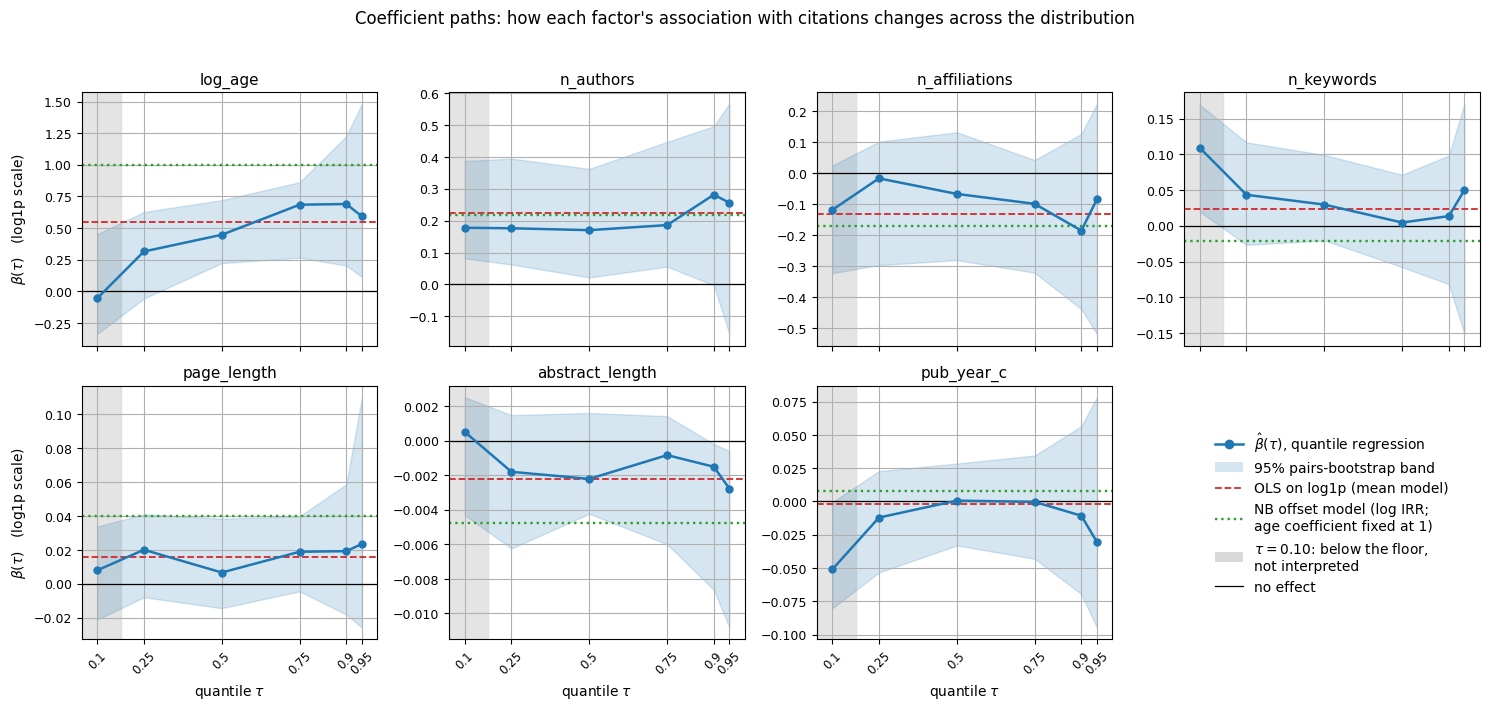

In [32]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

tau_arr = np.array(TAUS)
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), sharex=True)

for ax, var in zip(axes.ravel(), qr_cols):
    i = qr_names.index(var)
    ax.axvspan(0.05, 0.175, color="0.85", alpha=0.7, zorder=0)          # flagged low-tau region
    ax.fill_between(tau_arr, pct_lo[i], pct_hi[i], color="#1f77b4", alpha=0.18, zorder=1)
    ax.plot(tau_arr, pt[i], "o-", color="#1f77b4", lw=1.8, ms=5, zorder=3)
    ax.axhline(0, color="black", lw=0.9, zorder=2)
    ax.axhline(ols_log1p.params[i], color="#d62728", ls="--", lw=1.3, zorder=2)
    ax.axhline(nb_ref[var] if var in feat_cols else 1.0, color="#2ca02c", ls=":", lw=1.7, zorder=2)
    ax.set_title(var, fontsize=11)
    ax.set_xticks(tau_arr); ax.set_xticklabels([f"{t:g}" for t in TAUS], fontsize=8.5, rotation=45)
    ax.set_xlim(0.05, 1.0); ax.tick_params(axis="y", labelsize=9)

for ax in axes[1]:
    ax.set_xlabel(r"quantile $\tau$")
axes[0, 0].set_ylabel(r"$\beta(\tau)$   (log1p scale)")
axes[1, 0].set_ylabel(r"$\beta(\tau)$   (log1p scale)")

legend_ax = axes.ravel()[-1]
legend_ax.axis("off")
legend_ax.legend(handles=[
    Line2D([], [], color="#1f77b4", marker="o", lw=1.8, label=r"$\hat\beta(\tau)$, quantile regression"),
    Patch(facecolor="#1f77b4", alpha=0.18, label="95% pairs-bootstrap band"),
    Line2D([], [], color="#d62728", ls="--", lw=1.3, label="OLS on log1p (mean model)"),
    Line2D([], [], color="#2ca02c", ls=":", lw=1.7,
           label="NB offset model (log IRR;\nage coefficient fixed at 1)"),
    Patch(facecolor="0.85", label=r"$\tau=0.10$: below the floor," + "\nnot interpreted"),
    Line2D([], [], color="black", lw=0.9, label="no effect"),
], loc="center", frameon=False, fontsize=10)

fig.suptitle("Coefficient paths: how each factor's association with citations changes across the distribution", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 2.16 Reading the paths

Taking the panels one at a time, on the interpretable range $\tau \in [0.25,\, 0.95]$.

**`log_age` rises, and never reaches what the offset model assumes.** The path climbs from $0.315$ at $\tau = 0.25$ to $0.447$ at the median, $0.684$ at $\tau = 0.75$ and $0.690$ at $\tau = 0.90$, then eases back to $0.592$ at $\tau = 0.95$. It is significant at the median ($p = 0.0009$) and in the tail ($p = 0.0096$). Translated: a paper twice as old has $2^{0.4467} = 1.36$ times the citations at the median and $2^{0.69} = 1.61$ times in the tail. The offset in §2.4 asserts a factor of exactly $2.00$ at every quantile, and the free-age NB fit in §2.3 estimated $1.039$ on the log scale, also close to $2.00\times$. The quantile model disagrees with both at every level: citation accrual is clearly **sub-linear** in age, which is what Part 1's peak-and-decline shape predicts and what a linear offset cannot represent. The upward slope says the sub-linearity is worse near the median than in the tail, which is the same story in different words: typical papers stop accruing citations, well-cited ones keep going for longer.

**`n_authors` is the only paper-level factor with a visibly tail-shaped path.** It is essentially flat at $0.176$, $0.170$, $0.186$ across $\tau = 0.25,\, 0.50,\, 0.75$, then steps up to $0.281$ at $\tau = 0.90$ and $0.256$ at $\tau = 0.95$. It is the largest coefficient in the model at every quantile and the only covariate whose band stays on one side of zero for most of the range. The step in the top decile is the single most interesting shape in the figure, and §2.17 tests whether it is real.

**`n_affiliations` is negative almost everywhere, but never significantly so.** $-0.017$, $-0.067$, $-0.099$, $-0.185$, $-0.084$ across the grid, with $p = 0.53$ at the median and $p = 0.22$ in the tail. The NB reference line at $-0.171$ sits inside the bootstrap band at every quantile, so the quantile model is consistent with the NB's marginal result ($p = 0.0615$) without confirming it. What the sign means, conditional on author count, is that spreading the same number of authors across more institutions is not associated with more citations. That is a real distinction and §2.20 quantifies it.

**`n_keywords` does nothing at any quantile.** $0.043$, $0.030$, $0.005$, $0.014$, $0.050$, with $p \geq 0.32$ everywhere. Flat, small, and straddling zero. This agrees with the NB ($p = 0.529$). Keyword count is not a lever.

**`page_length` is flat and small, and the quantile model does not reproduce the NB's result.** The path runs $0.020$, $0.007$, $0.019$, $0.019$, $0.024$, never significant ($p = 0.62$ at the median, $p = 0.34$ in the tail). The NB offset model put this at $0.0397$ with $p = 0.0019$, making it one of that model's two strongest findings. That line sits above the entire quantile path, and at the median it falls outside the bootstrap band entirely (band $[-0.0144,\ 0.0384]$ against an NB value of $0.0397$). Either the NB is picking up something the quantile model cannot see, or the NB estimate is being driven by a handful of papers. §2.19 settles it.

**`abstract_length` is flat, negative, tiny, and not significant.** $-0.0018$ to $-0.0028$ across the grid, $p = 0.16$ at the median. The NB estimate of $-0.0048$ sits below the whole path and outside the median band ($[-0.0042,\ 0.0016]$), so again the quantile model finds roughly half the NB's effect. The magnitude is not negligible in practical terms: a one standard deviation longer abstract (38 words) is associated with about 10% fewer citations at the median. It is simply not distinguishable from zero at this sample size once the iid assumption is dropped.

**`pub_year_c` is flat at zero.** $0.001$ at the median, $-0.011$ in the tail, $p > 0.74$ throughout. §2.19 shows why this variable has nothing independent to contribute in the first place.

So of the six paper-level covariates, five have paths that are flat within noise. Only `n_authors` shows a shape that a mean model would have missed, and only `log_age` shows a slope that is large relative to its band. That is worth saying plainly: **the main finding of the coefficient-path exercise is that the paths are mostly flat**, which means the NB model's single-effect-per-covariate summary was not actually leaving much on the table for these six variables. What it was getting wrong was the age scaling and the stability of its own estimates, not the tail-versus-typical distinction.

## 2.17 Is the tail effect actually different from the median effect?

Eyeballing a path is not a test. The question "does this variable matter more for breakout papers than for typical ones" has a precise formal version:

$$
H_0: \; \beta_j(0.90) = \beta_j(0.50)
\qquad\text{against}\qquad
H_1: \; \beta_j(0.90) \neq \beta_j(0.50)
$$

There is no closed-form standard error for this difference that does not assume something about the joint distribution of the two estimators, so we take it straight from the bootstrap. Because every replicate refits *both* quantiles on the *same* resampled papers, the bootstrap distribution of $\hat\beta_j(0.90) - \hat\beta_j(0.50)$ automatically carries their correlation, and the resulting standard error is the correct one for the difference.

We also report the smallest gap the test could have detected: $2.80 \times \mathrm{SE}$ is the effect size a two-sided 5% test attains 80% power against. This is the number that tells you whether a null result means "no effect" or "not enough data".

In [33]:
i5, i9  = TAUS.index(0.50), TAUS.index(0.90)
d_hat   = pt[:, i9] - pt[:, i5]
d_boot  = boot[:, :, i9] - boot[:, :, i5]        # paired: same resample at both quantiles
d_se    = d_boot.std(axis=0, ddof=1)
p_diff  = 2 * (1 - stats.norm.cdf(np.abs(d_hat / d_se)))

diff_tbl = pd.DataFrame({
    "b(0.50)": pt[:, i5], "b(0.90)": pt[:, i9], "difference": d_hat, "boot SE": d_se,
    "2.5%": np.percentile(d_boot, 2.5, axis=0), "97.5%": np.percentile(d_boot, 97.5, axis=0),
    "p (boot)": p_diff, "gap detectable at 80% power": 2.80 * d_se,
}, index=qr_names).drop(index="Intercept")

print("H0: beta(0.90) = beta(0.50)   (paired pairs bootstrap, B = %d)\n" % B_REP)
print(diff_tbl.round(4).to_string())
print(f"\nsmallest p-value across the seven covariates: {p_diff[1:].min():.3f}")
print("bootstrap corr(b(0.90), b(0.50)):",
      "  ".join(f"{qr_names[i]} {np.corrcoef(boot[:, i, i9], boot[:, i, i5])[0, 1]:.2f}"
               for i in range(1, len(qr_names))))

H0: beta(0.90) = beta(0.50)   (paired pairs bootstrap, B = 500)

                 b(0.50)  b(0.90)  difference  boot SE    2.5%  97.5%  p (boot)  gap detectable at 80% power
log_age           0.4467   0.6899      0.2432   0.2609 -0.2188 0.7484    0.3514                       0.7307
n_authors         0.1701   0.2814      0.1113   0.1342 -0.2020 0.3441    0.4069                       0.3757
n_affiliations   -0.0667  -0.1848     -0.1182   0.1581 -0.3893 0.2150    0.4548                       0.4426
n_keywords        0.0297   0.0136     -0.0161   0.0486 -0.1151 0.0687    0.7403                       0.1362
page_length       0.0067   0.0192      0.0126   0.0212 -0.0271 0.0520    0.5531                       0.0594
abstract_length  -0.0022  -0.0015      0.0007   0.0023 -0.0065 0.0027    0.7596                       0.0064
pub_year_c        0.0007  -0.0107     -0.0114   0.0322 -0.0616 0.0611    0.7244                       0.0902

smallest p-value across the seven covariates: 0.351
bootstrap 

**No covariate shows a significant difference between its tail effect and its median effect.** The smallest $p$-value across the seven is $0.351$, for `log_age`. `n_authors`, the one with the most tail-shaped path, has an estimated gap of $+0.111$ with a bootstrap standard error of $0.134$ and a 95% interval of $[-0.202,\ 0.344]$, giving $p = 0.407$. Every other $p$-value is above $0.45$.

This is a null result and it should be reported as one, but it is a null result with a clear explanation. The power column says the test could only have detected a tail-minus-median gap of $0.376$ on the log scale for `n_authors`, which corresponds to the per-author effect being about **46% larger** in the tail than at the median. The gap actually observed is about 12%. The study is underpowered for this comparison by a factor of roughly three, which is unsurprising given that the $\tau = 0.90$ fit rests on the 56 papers above it (§2.12).

So the correct statement is **not** "the factors that drive high hitters are the same as the factors that drive typical papers". It is: *within the resolution of 582 papers from one journal, no paper-level covariate is shown to behave differently in the tail than at the median, and the effect sizes that would have been detectable are large ones.* A tail-specific mechanism of moderate size would have been invisible to this design. The point estimates hint at one for `n_authors` and the test cannot confirm it.

This also, incidentally, retrospectively rehabilitates the NB model's *coefficients*, if not its uncertainty estimates. If the effects genuinely do not differ across quantiles, then reporting one number per covariate is not obviously wrong. The problems with §2.4 turn out to lie elsewhere: in the age scaling (§2.16) and in the stability of the estimates (§2.19).

## 2.18 How much do these factors explain?

Quantile regression has no $R^2$, because there is no sum of squares to decompose. The standard goodness-of-fit measure is Koenker and Machado's (1999) $R^1(\tau)$, built from the same check loss the estimator minimises:

$$
R^1(\tau) \;=\; 1 \;-\; \frac{\hat V(\tau)}{\tilde V(\tau)},
\qquad
\hat V(\tau) = \sum_i \rho_\tau\!\left(y_i - \mathbf{x}_i^\top \hat{\boldsymbol\beta}(\tau)\right),
\qquad
\tilde V(\tau) = \sum_i \rho_\tau\!\left(y_i - \hat\beta_0(\tau)\right)
$$

$\tilde V(\tau)$ is the check loss of the intercept-only model, whose fit is just the unconditional $\tau$-quantile. So $R^1(\tau)$ is the proportion of the quantile-specific loss removed by knowing the covariates. It lies in $[0,1]$ and is local to $\tau$: a model can fit the median well and the tail badly, or the reverse.

We report it three ways per quantile: for the full model, for a model with `log_age` alone, and the difference between them. The third column is the one that matters for the client, because it isolates what the **paper-level** factors add once you already know how old the paper is, and age is not something an editor can act on.

In [34]:
def check_loss(u, tau):
    return (u * (tau - (u < 0))).sum()

X_null = np.ones((len(fsr), 1))
X_age  = sm.add_constant(fsr[["log_age"]]).to_numpy()

r1 = pd.DataFrame([{
    "tau": tau,
    "R1 (age + paper factors)": 1 - check_loss(y_qr - X_qr  @ qr_fit(X_qr,  y_qr, tau), tau)
                                  / check_loss(y_qr - X_null @ qr_fit(X_null, y_qr, tau), tau),
    "R1 (age alone)":           1 - check_loss(y_qr - X_age  @ qr_fit(X_age,  y_qr, tau), tau)
                                  / check_loss(y_qr - X_null @ qr_fit(X_null, y_qr, tau), tau),
} for tau in TAUS]).set_index("tau")
r1.index = [f"{t:.2f}" for t in TAUS]
r1["added by paper factors"] = r1["R1 (age + paper factors)"] - r1["R1 (age alone)"]

print("Koenker-Machado R1(tau) = 1 - (check loss, full model) / (check loss, intercept only)\n")
print(r1.round(4).to_string())
print(f"\nOLS R^2 on the same response, for comparison: {ols_log1p.rsquared:.4f}")

q50_hat = np.expm1(X_qr @ qr_coef["tau=0.50"].to_numpy())
q90_hat = np.expm1(X_qr @ qr_coef["tau=0.90"].to_numpy())
print(f"\nMedian fitted Q(0.90)/Q(0.50) ratio across the 582 papers: {np.median(q90_hat / q50_hat):.1f}x")
print(f"Spread of fitted Q(0.90) across papers: {q90_hat.min():.1f} to {q90_hat.max():.1f} citations")

Koenker-Machado R1(tau) = 1 - (check loss, full model) / (check loss, intercept only)

      R1 (age + paper factors)  R1 (age alone)  added by paper factors
0.10                    0.0958          0.0719                  0.0238
0.25                    0.0632          0.0457                  0.0175
0.50                    0.0734          0.0613                  0.0121
0.75                    0.0924          0.0781                  0.0143
0.90                    0.1011          0.0835                  0.0176
0.95                    0.1131          0.0919                  0.0213

OLS R^2 on the same response, for comparison: 0.1360

Median fitted Q(0.90)/Q(0.50) ratio across the 582 papers: 5.3x
Spread of fitted Q(0.90) across papers: 1.6 to 110.3 citations


The numbers are small and they should be taken at face value. Across the interpretable range the full model removes between 6.3% and 11.3% of the check loss, and most of that is age: `log_age` on its own accounts for $0.046$ to $0.092$, so the six paper-level covariates together add only **1.2 to 2.1 percentage points**. At the median the increment is $0.0121$; in the tail, where the question actually lives, it is $0.0176$.

Two honest readings follow.

First, the tail is marginally *more* predictable than the middle, not less: $R^1$ rises monotonically from $0.063$ at $\tau = 0.25$ to $0.113$ at $\tau = 0.95$. That runs against the intuition that breakout papers are pure noise. But the increment attributable to paper-level factors is around 2% in the tail, so "more predictable" here means "still almost entirely unpredictable, slightly less so".

Second, the residual conditional spread is enormous. Using the fitted surfaces, the median paper's fitted $Q(0.90)$ is **5.3 times** its fitted $Q(0.50)$. Two papers identical on every covariate in this model, including age, differ by a factor of more than five between a median outcome and a 90th-percentile outcome. Whatever separates an FSR high hitter from an ordinary FSR paper, roughly 98% of it is not author count, affiliation count, keyword count, page length, abstract length or publication year.

A note on comparability: OLS on the same response gives $R^2 = 0.136$, which looks larger than any $R^1$ here, but the two are not the same quantity. $R^2$ is computed against squared loss, which the tail observations inflate heavily, so it flatters the mean model. They are not directly comparable and neither is being reported as better than the other.

## 2.19 Robustness

Three checks, each aimed at a specific worry.

**(a) Outliers.** The claim that quantile regression is resistant to extreme $y$ values should be tested, not asserted. We drop the five most-cited papers (678, 346, 334, 279 and 218 citations, together 0.9% of the sample) and refit both the quantile models and the NB model of §2.4 on identical data, then measure how far each coefficient moves **in units of its own standard error**. Percentage change is the wrong metric here, because a 90% change in a coefficient that was indistinguishable from zero means nothing.

**(b) Age handling.** Part 1 found a median citation peak at 10 years with a 4–20 year interquartile range, and 39% of papers still censored as not yet peaked. Papers younger than that have not had a chance to show what they are, so an age control that is even slightly misspecified will leak age into the paper-level coefficients. We refit on `age >= 5` ($n = 515$) and on `age >= 10` ($n = 439$), the papers old enough to be near or past the typical peak, and check whether the covariate effects survive.

**(c) The `pub_year_c` problem.** `age` is defined as $2025 - \text{year}$ and `pub_year_c` as $\text{year} - \overline{\text{year}}$, so the two are related by an exact identity. Whether that leaves `pub_year_c` with any independent role is worth checking directly, and we refit without it.

In [35]:
top5_cut = fsr["cited_by"].nlargest(5).min()
no_year  = [c for c in qr_cols if c != "pub_year_c"]

variants = {
    "full sample":      (fsr,                          qr_cols),
    "drop top 5 cited": (fsr[fsr["cited_by"] < top5_cut], qr_cols),
    "age >= 5":         (fsr[fsr["age"] >= 5],         qr_cols),
    "age >= 10":        (fsr[fsr["age"] >= 10],        no_year),
    "no pub_year_c":    (fsr,                          no_year),
}
print("citation counts dropped:", sorted(fsr["cited_by"].nlargest(5).tolist(), reverse=True))
print("n per variant:", {k: len(d) for k, (d, _) in variants.items()})
print(f"\npub_year_c + age takes {(fsr['pub_year_c'] + fsr['age']).round(6).nunique()} distinct value "
      f"({(fsr['pub_year_c'] + fsr['age']).iloc[0]:.4f}): pub_year_c IS age, negated and shifted.")
print(f"corr(log_age, pub_year_c) = {np.corrcoef(fsr['log_age'], fsr['pub_year_c'])[0, 1]:.3f}"
      f"   on age >= 10: {np.corrcoef(fsr.loc[fsr['age'] >= 10, 'log_age'], fsr.loc[fsr['age'] >= 10, 'pub_year_c'])[0, 1]:.3f}")

for tau in [0.50, 0.90]:
    out = {lab: pd.Series(qr_fit(sm.add_constant(d[cc]).to_numpy(), d["log1p_cited"].to_numpy(), tau),
                          index=["Intercept"] + cc)
           for lab, (d, cc) in variants.items()}
    print(f"\n--- quantile regression, tau = {tau:.2f} ---")
    print(pd.DataFrame(out).reindex(qr_names).round(4).to_string())

# the same perturbations applied to the NB mean model of 2.4
nb_tbl = pd.DataFrame({lab: sm.NegativeBinomial(d["cited_by"].to_numpy(), sm.add_constant(d[feat_cols]),
                                                offset=np.log(d["age"].to_numpy())).fit(disp=0).params
                       for lab, (d, _) in variants.items() if lab != "no pub_year_c"})
nb_p = pd.DataFrame({lab: sm.NegativeBinomial(d["cited_by"].to_numpy(), sm.add_constant(d[feat_cols]),
                                              offset=np.log(d["age"].to_numpy())).fit(disp=0).pvalues
                     for lab, (d, _) in variants.items() if lab != "no pub_year_c"})
print("\n--- Negative Binomial offset model (log IRR), same subsamples ---")
print(nb_tbl.round(4).to_string())
print("\nNB p-values, full sample vs the 5 most-cited papers removed:")
print(pd.DataFrame({"p (full)": nb_p["full sample"], "p (drop top 5)": nb_p["drop top 5 cited"]})
        .loc[feat_cols].round(4).to_string())
d5 = variants["drop top 5 cited"][0]
X5 = sm.add_constant(d5[qr_cols]).to_numpy(); y5 = d5["log1p_cited"].to_numpy()
nb_se = res_offset.bse
shift = pd.DataFrame({
    "NB (mean)":   (nb_tbl["drop top 5 cited"] - nb_tbl["full sample"]).loc[feat_cols] / nb_se[feat_cols],
    "QR tau=0.50": (pd.Series(qr_fit(X5, y5, 0.50), index=qr_names) - qr_coef["tau=0.50"]).loc[feat_cols]
                   / pd.Series(boot_se[:, TAUS.index(0.50)], index=qr_names).loc[feat_cols],
    "QR tau=0.90": (pd.Series(qr_fit(X5, y5, 0.90), index=qr_names) - qr_coef["tau=0.90"]).loc[feat_cols]
                   / pd.Series(boot_se[:, TAUS.index(0.90)], index=qr_names).loc[feat_cols],
})
print("\nCoefficient shift when 5 of 582 papers (0.9% of the sample) are removed,")
print("measured in standard errors of the coefficient itself:")
print(shift.map(lambda v: f"{v:+.2f} SE").to_string())

# does the headline author effect survive on mature papers only?
sub  = fsr[fsr["age"] >= 10]
X_m  = sm.add_constant(sub[no_year]).to_numpy(); y_m = sub["log1p_cited"].to_numpy()
rng_m = np.random.default_rng(SEED)
boot_m = np.empty((300, X_m.shape[1], 2))
for b in range(300):
    ix = rng_m.integers(0, len(sub), len(sub))
    for j, t in enumerate([0.50, 0.90]):
        boot_m[b, :, j] = qr_fit(X_m[ix], y_m[ix], t)
print(f"\nMature papers only (age >= 10, n = {len(sub)}), B = 300 bootstrap:")
for j, t in enumerate([0.50, 0.90]):
    bm = qr_fit(X_m, y_m, t); sm_ = boot_m[:, :, j].std(axis=0, ddof=1)
    print(f"  tau={t:.2f}  " + "   ".join(
        f"{v}={bm[(['Intercept']+no_year).index(v)]:+.4f} (SE {sm_[(['Intercept']+no_year).index(v)]:.4f})"
        for v in ["n_authors", "n_affiliations", "page_length"]))

citation counts dropped: [678, 346, 334, 279, 218]
n per variant: {'full sample': 582, 'drop top 5 cited': 577, 'age >= 5': 515, 'age >= 10': 439, 'no pub_year_c': 582}

pub_year_c + age takes 1 distinct value (15.6432): pub_year_c IS age, negated and shifted.
corr(log_age, pub_year_c) = -0.914   on age >= 10: -0.987



--- quantile regression, tau = 0.50 ---
                 full sample  drop top 5 cited  age >= 5  age >= 10  no pub_year_c
Intercept             0.3872            0.4252   -2.7097     1.6402         0.3617
log_age               0.4467            0.4417    1.7530     0.1699         0.4434
n_authors             0.1701            0.1666    0.2314     0.1519         0.1734
n_affiliations       -0.0667           -0.0480   -0.1246    -0.0434        -0.0669
n_keywords            0.0297            0.0257   -0.0284     0.0313         0.0294
page_length           0.0067            0.0038    0.0050    -0.0089         0.0070
abstract_length      -0.0022           -0.0022   -0.0032    -0.0035        -0.0021
pub_year_c            0.0007            0.0010    0.0899        NaN            NaN

--- quantile regression, tau = 0.90 ---
                 full sample  drop top 5 cited  age >= 5  age >= 10  no pub_year_c
Intercept             0.9505            0.8473   -3.3480     3.5162         0.5550
log_a


Mature papers only (age >= 10, n = 439), B = 300 bootstrap:
  tau=0.50  n_authors=+0.1519 (SE 0.1376)   n_affiliations=-0.0434 (SE 0.1362)   page_length=-0.0089 (SE 0.0201)
  tau=0.90  n_authors=+0.2585 (SE 0.1807)   n_affiliations=-0.2687 (SE 0.2131)   page_length=+0.0435 (SE 0.0242)


**(a) The outlier check is decisive, and it goes against the NB model.** Removing 5 papers out of 582 moves the NB coefficient on `page_length` by $2.81$ standard errors and on `pub_year_c` by $2.08$. The consequences for inference are total: `page_length` goes from $p = 0.0019$ to $p = 0.755$, so the NB's second-strongest result disappears, while `pub_year_c` goes from $p = 0.384$ to $p = 0.0019$, so a result that did not exist appears. `n_authors` drops from $p = 0.0063$ to $p = 0.0665$. Only `abstract_length` survives intact ($p = 0.0014 \to 0.0080$).

The same deletion moves the median quantile regression coefficients by **at most 0.21 standard errors**, and the $\tau = 0.90$ coefficients by at most 0.77. The author-count coefficient moves by 0.04 SE at the median and 0.33 SE in the tail. This is the practical payoff of the check loss being linear rather than quadratic: five papers cannot rewrite the answer. It also explains the §2.16 discrepancy on `page_length`. The NB's significant page-length effect was a property of five papers, not of the journal, and the quantile model was right not to reproduce it.

**(b) The author effect survives on mature papers.** Restricting to `age >= 5` gives $0.231$ at the median and $0.295$ in the tail, slightly larger than the full-sample $0.170$ and $0.281$. Restricting to `age >= 10` gives $0.152$ (SE $0.138$) and $0.259$ (SE $0.181$), slightly smaller. Both sit comfortably inside the full-sample bootstrap interval, so the association is not an artefact of young papers being pooled with old ones. The step up in the tail is present in every one of the four specifications: $0.281$, $0.239$, $0.295$, $0.259$. It is stable in sign and rough size, and (per §2.17) never significantly different from the median effect.

`n_affiliations` becomes more negative on mature papers ($-0.269$ at $\tau = 0.90$, SE $0.213$) and `page_length` becomes more positive ($+0.0435$, SE $0.0242$, so $z \approx 1.8$). Neither crosses conventional significance, and the mature subsample is 25% smaller, so these are drifts within noise rather than new findings.

**(c) `pub_year_c` is not a separate control, it is age again.** `pub_year_c + age` takes exactly one distinct value across all 582 papers ($15.6432$), which is the arithmetic consequence of both being fixed functions of `year` with the observation window ending in 2025. There is no era effect in this data that is separable from an age effect, because every paper was observed until the same calendar date. Including both `log_age` and `pub_year_c` therefore fits a flexible two-parameter curve in age, not an age effect plus a period effect, and neither coefficient is interpretable on its own. The correlation is $-0.914$ on the full sample and $-0.987$ once restricted to `age >= 10`, which is why `log_age` takes wild values in the age-restricted columns ($1.75$ and $2.28$ on `age >= 5`, where both terms are retained): the split between the two terms is arbitrary when they are nearly collinear.

Dropping `pub_year_c` entirely changes the paper-level coefficients hardly at all ($0.1734$ vs $0.1701$ for `n_authors` at the median, $0.2761$ vs $0.2814$ in the tail). The substantive conclusions do not depend on the age parameterisation. Only the age coefficient does, and it should be read as one curve rather than two numbers. The stage-2 concern about age conflation is real, but it lands on the age terms, not on the covariates the editorial team would act on.

## 2.20 From coefficients to citations

Coefficients on a $\log(1+y)$ scale are not something to hand an editorial board. This section converts them, using the exact quantile-to-quantile transformation from §2.11 rather than the $\exp(\beta) - 1$ shortcut, evaluated at the average FSR paper. Then it does the same at age 10, the median citation peak age from Part 1, so the numbers describe a paper at the point where Part 1 says it is reasonable to judge it.

One contrast is worth separating out. `n_authors` is positive and `n_affiliations` is negative, and both are in the model at once, so "add a co-author" means different things depending on where the co-author comes from. Adding an author at an institution already represented moves only `n_authors`; adding one at a new institution moves both, and the relevant effect is the **sum** of the two coefficients. The bootstrap gives a standard error for that sum directly.

In [36]:
x_bar = X_qr.mean(axis=0)

def q_at(x, tau):
    return np.expm1(x @ qr_coef[f"tau={tau:.2f}"].to_numpy())

deltas = {"n_authors": 1, "n_affiliations": 1, "n_keywords": 1,
          "page_length": 5, "abstract_length": round(fsr["abstract_length"].std())}
rows = []
for var, dlt in deltas.items():
    r = {"change": f"+{dlt:g} {var}"}
    for tau in [0.50, 0.90]:
        x2 = x_bar.copy(); x2[qr_names.index(var)] += dlt
        q0, q1 = q_at(x_bar, tau), q_at(x2, tau)
        r[f"Q({tau:.2f}) from"] = f"{q0:.2f}"
        r[f"Q({tau:.2f}) to"]   = f"{q1:.2f}"
        r[f"tau={tau:.2f}"]     = f"{100 * (q1 / q0 - 1):+.1f}%"
    rows.append(r)
print("Average FSR paper: age %.1f years, %.2f authors, %.1f affiliations, %.1f pages, %.0f-word abstract\n"
      % (fsr["age"].mean(), fsr["n_authors"].mean(), fsr["n_affiliations"].mean(),
         fsr["page_length"].mean(), fsr["abstract_length"].mean()))
print(pd.DataFrame(rows).set_index("change").to_string())

print("\nReading a coefficient as a percentage understates the effect at small counts:")
for tau in [0.50, 0.90]:
    b  = qr_coef.loc["n_authors", f"tau={tau:.2f}"]
    x2 = x_bar.copy(); x2[qr_names.index("n_authors")] += 1
    print(f"  +1 author at tau={tau:.2f}:  exp(beta)-1 = {100*np.expm1(b):+.1f}%    exact = {100*(q_at(x2, tau)/q_at(x_bar, tau)-1):+.1f}%")

la  = np.log(10)
pyc = float((fsr["pub_year_c"] + fsr["age"]).iloc[0]) - 10
print("\nFitted citation quantiles at age = 10 (the Part 1 median peak age), everything else at its mean:")
print("  n_authors" + "".join(f"  Q({t:.2f})" for t in TAUS))
for na in [1, 2, 3, 4]:
    x = x_bar.copy()
    x[qr_names.index("log_age")]    = la
    x[qr_names.index("pub_year_c")] = pyc
    x[qr_names.index("n_authors")]  = na
    print(f"  {na:9d}" + "".join(f"{q_at(x, t):9.1f}" for t in TAUS))
print(f"\nThe raw top-10% 'high hitter' cutoff used in 2.6 is {fsr['cited_by'].quantile(0.90):.0f} citations.")

Average FSR paper: age 16.8 years, 2.23 authors, 1.7 affiliations, 16.2 pages, 123-word abstract

                    Q(0.50) from Q(0.50) to tau=0.50 Q(0.90) from Q(0.90) to tau=0.90
change                                                                               
+1 n_authors                4.68       5.74   +22.5%        24.17      32.36   +33.8%
+1 n_affiliations           4.68       4.32    -7.8%        24.17      19.93   -17.6%
+1 n_keywords               4.68       4.85    +3.7%        24.17      24.52    +1.4%
+5 page_length              4.68       4.87    +4.1%        24.17      26.72   +10.5%
+38 abstract_length         4.68       4.23    -9.8%        24.17      22.78    -5.8%

Reading a coefficient as a percentage understates the effect at small counts:
  +1 author at tau=0.50:  exp(beta)-1 = +18.5%    exact = +22.5%
  +1 author at tau=0.90:  exp(beta)-1 = +32.5%    exact = +33.8%

Fitted citation quantiles at age = 10 (the Part 1 median peak age), everything else at its

In [37]:
ia, ifa = qr_names.index("n_authors"), qr_names.index("n_affiliations")
print("Adding a co-author at an EXISTING institution vs at a NEW one:\n")
for tau in [0.50, 0.90]:
    j = TAUS.index(tau)
    same = pt[ia, j]
    new  = pt[ia, j] + pt[ifa, j]
    bs_same, bs_new = boot[:, ia, j], boot[:, ia, j] + boot[:, ifa, j]
    print(f"  tau={tau:.2f}  same institution: {same:+.4f} (SE {bs_same.std(ddof=1):.4f}, "
          f"95% [{np.percentile(bs_same,2.5):+.4f}, {np.percentile(bs_same,97.5):+.4f}])"
          f"  -> {100*np.expm1(same):+.1f}%")
    print(f"            new institution : {new:+.4f} (SE {bs_new.std(ddof=1):.4f}, "
          f"95% [{np.percentile(bs_new,2.5):+.4f}, {np.percentile(bs_new,97.5):+.4f}])"
          f"  -> {100*np.expm1(new):+.1f}%")
print("\nAge scaling: a paper twice as old has this many times the citations (1+Q basis)")
print("  " + "  ".join(f"tau={t:.2f}: {2**qr_coef.loc['log_age', f'tau={t:.2f}']:.2f}x" for t in TAUS))
print("  the NB offset model assumes exactly 2.00x at every quantile.")
print("\nPower: the tail-minus-median gap we could have detected at 80% power, as a % difference")
print("  in the per-unit effect, vs the gap actually observed:")
for i in range(1, len(qr_names)):
    print(f"  {qr_names[i]:16s} detectable {100*np.expm1(2.80*d_se[i]):6.1f}%   observed {100*np.expm1(d_hat[i]):+7.1f}%")

Adding a co-author at an EXISTING institution vs at a NEW one:

  tau=0.50  same institution: +0.1701 (SE 0.0896, 95% [+0.0217, +0.3626])  -> +18.5%
            new institution : +0.1035 (SE 0.0855, 95% [-0.0455, +0.2787])  -> +10.9%
  tau=0.90  same institution: +0.2814 (SE 0.1312, 95% [-0.0029, +0.4965])  -> +32.5%
            new institution : +0.0966 (SE 0.1173, 95% [-0.1177, +0.3446])  -> +10.1%

Age scaling: a paper twice as old has this many times the citations (1+Q basis)
  tau=0.10: 0.96x  tau=0.25: 1.24x  tau=0.50: 1.36x  tau=0.75: 1.61x  tau=0.90: 1.61x  tau=0.95: 1.51x
  the NB offset model assumes exactly 2.00x at every quantile.

Power: the tail-minus-median gap we could have detected at 80% power, as a % difference
  in the per-unit effect, vs the gap actually observed:
  log_age          detectable  107.6%   observed   +27.5%
  n_authors        detectable   45.6%   observed   +11.8%
  n_affiliations   detectable   55.7%   observed   -11.1%
  n_keywords       detectable 

Three things fall out of these numbers.

**Author count is the only factor with a practically meaningful association, and it is modest.** One extra author is associated with about 22% more citations for a typical paper and about 34% more at the 90th percentile of its conditional distribution. That is a real difference but it is not the difference between an ordinary paper and a high hitter, which in this corpus is a factor of five or more (§2.18).

**Where the co-author comes from appears to matter more than that they exist.** At the median, adding a co-author at an institution already on the paper is associated with $+18.5\%$, and adding one at a new institution with $+10.9\%$. In the tail the gap is wider: $+32.5\%$ versus $+10.1\%$. Both sums have wide intervals and neither difference is formally tested here, so this is a pattern to note rather than a finding to act on. It does cut against the common assumption that cross-institutional collaboration is what drives citations, at least within this journal.

**Nothing else moves the needle.** A keyword is worth $+3.7\%$ at the median and $+1.4\%$ in the tail, neither significant. Five extra pages are worth $+4.1\%$ and $+10.5\%$, neither significant, and §2.19 showed the mean model's apparently strong page-length result was carried by five papers. A standard-deviation longer abstract (38 words) is associated with about 10% fewer citations at the median, which is not trivial in size but is not distinguishable from zero.

The age-10 table is the most directly useful output for an editor. For an otherwise average FSR paper judged at the Part 1 median peak age, the fitted 90th-percentile outcome runs from **12.6 citations for a solo-authored paper to 30.6 for a four-author paper**. The top-10% cutoff used in §2.8.1 is 26 citations. So even at the top of its own conditional distribution, an average solo-authored FSR paper would not clear the high-hitter bar at year 10, while a four-author one would. That is the largest single piece of discrimination anything in this model achieves, and the confidence interval around the author coefficient means even that is provisional. Note that the $Q(0.10)$ column in that table is negative for a solo-authored paper, which is the floor problem from §2.12 showing up exactly where it was predicted to.

## 2.21 What this means for FSR

Question D has two halves: **when** to judge a paper, and **what to look for**. Part 1 answered the first with a Kaplan-Meier estimate of the time to citation peak: a median of 10 years, and 39% of papers still censored as not yet peaked. The raw interquartile range of 4 to 20 years did not survive the robustness work in §1.7 and should be read as an upper bound on dispersion rather than an estimate of it. This section answers the second, and the answer is largely negative.

### When to judge

Part 1's median of 10 years is confirmed and sharpened by the age path here. Citation accrual is strongly sub-linear: doubling a paper's age multiplies its citation count by about $1.36$ at the median and $1.61$ at the 90th percentile, not by 2 as the Negative Binomial offset assumed. So the marginal year of age buys progressively less, which is the arithmetic signature of the peak-and-decline shape Part 1 found. Two practical consequences:

- **Separate the two things an early judgement is being asked to do.** Part 1 found that the *ranking* information saturates early: Spearman correlation against future citations plateaus at about age 6 and does not improve through age 10 (§1.10). The *magnitude* does not saturate at all, and this section shows why, since citation accrual stays sub-linear well past the median peak. At five years a paper's eventual standing is roughly knowable while its eventual citation count is not. Five to six years is therefore the right point to judge which papers are working, and 10 years the right point to judge how much they were worth. With 39% of papers still climbing at the data cut-off, any early screen will misclassify a substantial minority either way.
- **The papers most likely to be misjudged early are exactly the ones the client cares about.** The age coefficient is larger at $\tau = 0.90$ than at $\tau = 0.50$ ($0.690$ versus $0.447$), meaning well-cited papers keep accruing for longer than typical ones. An early call is therefore systematically less reliable for tail papers than for median papers. The difference is not statistically significant (§2.17), but the sign is consistent across the whole upper half of the grid, and it matches Part 1's finding that the failure mode of a five-year window is promoting flashes in the pan rather than missing eventual winners (§1.10).

### What to look for

Of the six paper-level factors available in this dataset, **one carries any signal and five do not**:

| Factor | Typical paper ($\tau = 0.50$) | Tail ($\tau = 0.90$) | Verdict |
|---|---|---|---|
| `n_authors` | $+22.5\%$ per author | $+33.8\%$ per author | Consistently positive, borderline significant, largest effect in the model |
| `n_affiliations` | $-7.8\%$ | $-17.6\%$ | Negative throughout, never significant |
| `page_length` | $+4.1\%$ per 5 pages | $+10.5\%$ per 5 pages | Not significant; the NB's significant result was 5 papers |
| `abstract_length` | $-9.8\%$ per 38 words | $-5.8\%$ | Not significant once the iid assumption is dropped |
| `n_keywords` | $+3.7\%$ | $+1.4\%$ | Flat at zero at every quantile |
| `pub_year_c` | $\approx 0$ | $\approx 0$ | Not identifiable separately from age |

And the direct answer to "do the factors that produce high hitters differ from the factors that produce typical papers": **no covariate is shown to behave differently in the tail**, smallest $p = 0.351$. The paths are mostly flat. `n_authors` steps up from about $0.18$ to about $0.28$ in the top decile, which is the one shape that looks tail-specific, and the test cannot distinguish it from noise. The design could only have detected a tail-versus-median gap of about 46% in the per-author effect; the observed gap is about 12%.

### How much should the editorial team expect from acting on this?

Very little, and this is the most important number in the section. Once you already know a paper's age, the six paper-level factors together reduce the quantile-specific loss by **1.2 percentage points at the median and 1.8 in the tail** ($R^1$ increments, §2.18). Conditional on everything in this model, a paper's 90th-percentile outcome is still about 5.3 times its median outcome. Roughly 98% of what separates an FSR high hitter from an ordinary FSR paper is not captured by author count, affiliation count, keyword count, page length, abstract length or publication year.

That is not a failure of the model. It is a finding, and a useful one: **the metadata an editor sees at submission does not predict citation outcomes.** Concretely:

1. **Do not build a metadata screen.** There is no combination of these variables that identifies high hitters well enough to act on, and §2.8.1's confusion matrix already showed the mean model doing poorly at the same task. Any "promising paper" heuristic built on structural metadata would be close to random.
2. **Do not impose format rules expecting citations.** Keyword counts are flat at zero at every quantile. Page-length and abstract-length effects are not significant, and the page-length result that looked strong under the mean model evaporated when five papers were removed. A minimum-keyword or minimum-length policy has no support here.
3. **Multi-author submissions are worth modestly more citations, and the effect is not a policy lever anyway.** An editor cannot add authors to a submitted paper. The finding is descriptive: FSR's more-cited papers tend to have more authors, plausibly because larger teams bring larger citing networks, broader scope or more promotion capacity. If it is a lever at all it is a commissioning lever, not an editorial one.
4. **Judge which papers are working at five to six years, and how much they were worth at ten.** Expect to be wrong often, and to be wrong more often about the papers you most want to identify. §1.11 sets out the operational version of this, including the cohort trend that is pulling FSR's peak timing earlier.
5. **The real drivers are somewhere else.** These six variables are structural metadata. They contain nothing about topic, method, data source, writing quality, author standing, or post-publication promotion. A 2% incremental fit is evidence that the answer lies in the content and the dissemination, which is where the rest of the project should look.

### What this analysis can and cannot support

It can support statements about **association within FSR's published corpus**: which observable features co-occur with higher citation quantiles among 582 papers published in one journal and observed to the end of 2025.

It cannot support causal statements. This is observational data with no randomisation, no control group, and no identification strategy. Author count is not assigned, it is chosen, and it is correlated with unmeasured things (project scope, funding, seniority, network size) that plausibly drive citations on their own. The brief's own framing is right: the evidence base in this literature is "rarely causal" (Kousha and Thelwall, 2024), and nothing here changes that. "Papers with more authors are cited more" is supported; "adding an author would cause more citations" is not.

Three further limits worth stating plainly:

- **Single journal, single field.** FSR is a Diamond Open Access journal in personal financial planning. Nothing here transfers to other journals or fields without checking.
- **Survivorship.** This is the published corpus. Rejected submissions are not observed, so every association is conditional on having been accepted by FSR.
- **Power.** At $N = 582$ with 56 papers above the $\tau = 0.90$ fit, moderate tail-specific effects are simply not detectable. Pooling the other two journals in `master_dataset.csv`, or extending the FSR back-catalogue, would be the direct way to give the §2.17 test enough power to distinguish a tail effect from a location shift. That is the natural next step, and it is the one change that would most improve this analysis.